# Flux post-processing chain: IRGA72 CO2 flux (2016-2026.09)

**notebook version**: `11` (26 Oct 2026). Adapted from the diive notebook `FluxPostProcessingChain.ipynb`.

## ℹ️ About this notebook

This notebook processes the CO2 flux (`FC`) of the closed-path **IRGA72** analyser for the release
**FP2026.1** (2016 to September 2026). It adds the
storage term, removes poor-quality records and outliers, fills the gaps, and splits the flux into
gross primary production (GPP) and ecosystem respiration (RECO). The steps follow the levels of the
Swiss FluxNet workflow:

| Level | What it does | Function |
|---|---|---|
| L2 | Quality flags from the EddyPro output | `run_level2` |
| L3.1 | Adds the storage term | `run_level31` |
| L3.2 | Removes outliers | `make_level32_detector` + `run_level32` |
| L3.3 | Removes records with weak turbulence (USTAR filter), for three thresholds | `run_level33_constant_ustar` |
| L4.1 | Fills the gaps with XGBoost | `run_level41_xgb` |
| L4.2 | Splits the flux into GPP and RECO (nighttime and daytime method of ONEFlux) | `run_level42_partitioning` |
| | Random, USTAR and joint uncertainty (Pastorello et al. 2020) | `RandomUncertaintyPAS20`, `JointUncertaintyPAS20` |

Each step takes the data and returns a new copy, so a step can be repeated without running the
earlier ones again.

The notebook runs on the whole record (`YEARS = None`). `TEST_RUN = True` runs a test on one year
(`TEST_YEAR`), and a list of years in `YEARS` on those years only; a test writes its own output
file. Level 4.2 is not part of this version of the dataset (`RUN_PARTITIONING = False`).

Level 2 and the USTAR thresholds are those of the 2016-2024 notebooks in this folder
(`01_FPC_L3.3_…` and `03_FPC_L4.1_…`). The other steps differ from them: the storage term is
screened for spikes (Level 3.1), the outlier tests are partly new (Level 3.2 keeps the absolute
limits of ±50 and replaces trimming of low values and the local standard deviation test with two
Hampel filters and a test of negative nighttime values), and the gaps
are filled with XGBoost instead of a random forest (Level 4.1).

***

## 📇 Data sources

The input is `30_FLUX_POST-PROCESSING_CHAIN/IRGA72/00_FPPC_IRGA72_INPUT_2016-2026.09.parquet` in the
external data folder. It holds the Level-1 fluxes of all 18 `IRGA72` runs together with the meteo
data of `10_METEO/30_PRODUCTS/99`, from 1 January 2016 00:15 to 30 September 2026 23:45
(`TIMESTAMP_MIDDLE`, UTC+01:00). The flux columns are empty before the first `IRGA72` record on
11 January 2016.

**Meteo drivers.** Gap-filling and partitioning use three complete meteo series: air temperature
(`TA_T1_47_1_HOMOGENIZED_gfXG`), vapour pressure deficit (`VPD_T1_47_1_HOMOGENIZED`) and incoming
shortwave radiation (`SW_IN_T1_47_1_gfXG`). Temperature and VPD are the homogenised versions, which
correct for the probe changes in 2016 and June 2026. The ONEFlux partitioning also needs *measured*
temperature and radiation. Step 6 builds them from the same series by keeping only the records
flagged as measured (`ISFILLED` code `0`).

**Periods to keep in mind.**

- **Start-up of the LI-7200 in 2016.** During the installation (11 to 22 January) and a period with
  too low a flow rate (1 March to 25 May), water in the filter lowered the fluxes. Level 3.2 removes
  both periods by hand, as the 2016-2024 notebooks did.
- **19 May to 7 June 2018.** There is no `FC`. The flow module of the analyser had failed, so this
  period was processed with the sonic anemometer only.
- **30 December 2018 to 10 January 2019.** The LI-7200 (IRGA72-B) was failing: its signal strength
  was low from December, the inlet filter was iced, it sent error codes, and its data acquisition
  stopped repeatedly. It was replaced on 11 January 2019. Level 3.2 removes the period by hand.
- **8 November to 6 December 2020.** A fault of the gas analyser. From 8 November the scatter of
  the flux rose to many times its usual level, with half-hourly values from -190 to +190
  µmol m-2 s-1 and implausible `LE`, while the flow rate and the sonic (`H`) stayed normal. The
  signal strength fell from 100 to about 60 on 12 November, the threshold of Level 2, rose to 80 on
  27 November and to 100 after the LI-7200 was replaced on 10 December. Level 3.2 removes 8 to
  27 November and 4 to 6 December by hand; the days between them are within the usual scatter.
- **15 January to 4 February 2026.** The nighttime scatter of the flux was about twice its
  seasonal level, also after the outlier tests, and winter daytime values above 20 µmol m-2 s-1
  occurred, which the same weeks of other years do not show. The signal strength fell from 93 to 87
  on 28 January. The scatter ended when the LI-7200 was cleaned on 4 February 2026, and the signal
  strength returned to 100. The calm nights of 18 to 23 January (USTAR 0.15-0.24 m s-1) add to
  the scatter but do not explain it, because it remains in the records that pass the USTAR filter.
  Level 3.2 removes the period by hand.
- **Long gaps without `FC`.** The model fills these gaps without measurements nearby: 1 to
  22 January 2016 (before and during the installation), 18 May to 7 June 2018 (flow module),
  10 January to 20 March 2019 (both LI-7200 units defective, then the LI-7500 as a stand-in, whose
  fluxes are not part of this dataset), 18 December 2020 to 4 January 2021, and 13 December 2021 to
  7 February 2022 (raw data that cannot be converted).
- **Wrong calibration gas, 14 December 2017 to 15 March 2019.** All `IRGA72` CO2 concentrations of
  this period were calibrated against the wrong reference gas. The correction, a factor of 0.974 on
  the concentration, has to be applied before the flux is calculated. It was applied during the
  conversion of the raw data to ASCII with bico, so `FC` is already corrected.

## ⚙️ Settings

In [1]:
# --- Source ------------------------------------------------------------------------------------
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow")
SOURCEFILE = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA72\00_FPPC_IRGA72_INPUT_2016-2026.09.parquet"

# --- Testing -----------------------------------------------------------------------------------
# TEST_RUN = True processes only TEST_YEAR, a quick check of the whole notebook. A test run writes
# its own output file, so it never overwrites the result of a full run.
TEST_RUN = False
TEST_YEAR = 2025
# Years to process. None processes the whole record; set from TEST_RUN, or give a list of years.
YEARS = [TEST_YEAR] if TEST_RUN else None
RUN_PARTITIONING = False  # Level 4.2, not part of this version of the dataset

# The full record, asserted after loading when YEARS is None.
PERIOD_START, PERIOD_END = '2016-01-01 00:15', '2026-09-30 23:45'

# --- Output ------------------------------------------------------------------------------------
OUTNAME = "01_FPPC_IRGA72_NEE_2016-2026.09"  # same name as this notebook
if YEARS:
    OUTNAME += f"_TEST_{'_'.join(str(_y) for _y in YEARS)}"
OUTPATH = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA72"

# --- Site and flux -----------------------------------------------------------------------------
FLUXCOL = 'FC'  # CO2 flux of the closed-path LI-7200; no self-heating correction is needed
SITE_LAT = 47.478333  # CH-LAE
SITE_LON = 8.364389
UTC_OFFSET = 1  # timestamps are UTC+01:00 all year
NIGHTTIME_THRESHOLD = 20  # W m-2 potential radiation below this = nighttime
DAYTIME_ACCEPT_QCF_BELOW = 2  # keep QCF 0 and 1
NIGHTTIME_ACCEPT_QCF_BELOW = 2

# --- Level 2 -----------------------------------------------------------------------------------
LEVEL2_SETTINGS = {
    'signal_strength': {'apply': True,
                        'signal_strength_col': 'CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN',
                        'method': 'discard below',
                        'threshold': 60},
    'raw_data_screening_vm97': {'apply': True,
                                'spikes': True, 'amplitude': False, 'dropout': True,
                                'abslim': False, 'skewkurt_hf': False, 'skewkurt_sf': False,
                                'discont_hf': False, 'discont_sf': False},
    'ssitc': {'apply': True, 'setflag_timeperiod': None},
    'gas_completeness': {'apply': False},
    'spectral_correction_factor': {'apply': True},
    'angle_of_attack': {'apply': False, 'application_dates': []},
    'steadiness_of_horizontal_wind': {'apply': False},
}

# --- Level 3.1 ---------------------------------------------------------------------------------
# The CO2 concentration the storage term SC_SINGLE is calculated from (mmol m-3). Next to a gap in
# it, the storage term is discarded where the analyser read off, and filled.
CO2_CONC = 'CO2_MOLAR_DENSITY'

# --- Level 3.2 ---------------------------------------------------------------------------------
# Periods removed by hand (date ranges, whole days, both ends included). The reasons are in
# *Data sources*.
REMOVE_DATES = [
    ['2016-01-11', '2016-01-22'],  # LI-7200 installation, water in the filter
    ['2016-03-01', '2016-05-25'],  # too low a flow rate, water in the filter
    ['2018-12-30', '2019-01-10'],  # failing LI-7200 (IRGA72-B), replaced on 11 January 2019
    ['2020-11-08', '2020-11-27'],  # gas analyser fault: flux scatter, signal strength down to 60
    ['2020-12-04', '2020-12-06'],  # same fault, before the LI-7200 was replaced on 10 December
    ['2026-01-15', '2026-02-04'],  # raised scatter until the LI-7200 was cleaned on 4 February
]
# Absolute limits (umol m-2 s-1), as in the 2016-2024 notebooks.
ABSLIM = (-50, 50)

# --- Level 3.3 ---------------------------------------------------------------------------------
# Constant USTAR thresholds (m s-1), the 16th, 50th and 84th percentiles of the bootstrap
# detection of the 2016-2024 record (stage 32_). This dataset uses these fixed thresholds for the
# whole record.
USTAR_THRESHOLDS = [0.271619922, 0.303628125, 0.339684084]
USTAR_SCENARIOS = ['CUT_16', 'CUT_50', 'CUT_84']

# --- Level 4.1 and 4.2: meteo drivers ----------------------------------------------------------
TA_F = 'TA_T1_47_1_HOMOGENIZED_gfXG'    # degC, complete
SW_IN_F = 'SW_IN_T1_47_1_gfXG'          # W m-2, complete
VPD_F = 'VPD_T1_47_1_HOMOGENIZED'       # kPa, complete
TA_FLAG = 'FLAG_TA_T1_47_1_ISFILLED'    # 0 = measured at 47 m
SW_IN_FLAG = 'FLAG_SW_IN_T1_47_1_ISFILLED'
VPD_FLAG = 'FLAG_VPD_T1_47_1_ISFILLED'
TA_MEAS = 'TA_T1_47_1_HOMOGENIZED_MEASURED'  # built below from TA_F and TA_FLAG
SW_IN_MEAS = 'SW_IN_T1_47_1_MEASURED'        # built below from SW_IN_F and SW_IN_FLAG
FEATURES = [TA_F, SW_IN_F, VPD_F]

FLUX_UNITS = 'µmol m-2 s-1'
RANDUNC_COL = 'FC_RANDUNC_HF'  # random uncertainty of FC from EddyPro
NIGHT_Z = 3  # night values below -NIGHT_Z times their uncertainty are removed in Level 3.2

# 30-min CO2 flux in umol m-2 s-1 -> gC m-2 per half-hour, for sums and cumulatives.
UMOL_TO_GC = 12.011 * 1e-6 * 1800

# MDS gap-filling, next to XGBoost, to compare the two methods. mode='diive' fills every gap,
# also long ones; the QC flags keep model-filled driver values out of the similar samples.
RUN_MDS = True
MDS_SETTINGS = dict(mode='diive', fill_long_gaps=True)

# XGBoost hyperparameters, at the production values suggested by the diive notebook.
XGB_SETTINGS = dict(n_estimators=350, max_depth=6, learning_rate=0.05,
                    early_stopping_rounds=10, random_state=42, n_jobs=-1, shap_max_rows=5000)

# --- Uncertainty -------------------------------------------------------------------------------
# Pastorello et al. (2020): random uncertainty of the reference scenario, USTAR uncertainty from
# the two outer scenarios.
UNC_REF = 'CUT_50'
UNC_LOWER, UNC_UPPER = 'CUT_16', 'CUT_84'

In [2]:
from datetime import datetime
import importlib.metadata
import warnings

import diive as dv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from diive.core.ml.feature_engineer import FeatureEngineer
from diive.core.plotting.styles import chainplots as cp
from diive.core.times.times import doy_cumulatives_per_year, doy_mean_cumulative
from diive.flux.postprocessingchain import (
    add_driver,
    init_flux_data,
    make_level32_detector,
    nighttime_uncertainty,
    run_level2,
    run_level31,
    run_level32,
    run_level33_constant_ustar,
    run_level41_mds,
    run_level41_xgb,
    run_level42_partitioning,
    # Reporting over the finished chain
    plot_feature_ranks_per_year,
    plot_gapfilled_cumulative,
    plot_gapfilling_comparison,
    plot_gapfilling_input,
    plot_quality_heatmaps,
    plot_quality_timeseries,
    report_annual_sums,
    report_gapfilling_comparison,
    report_gapfilling_feature_importances,
    report_gapfilling_input,
    report_gapfilling_model_scores,
    report_gapfilling_poolyears,
    report_gapfilling_variables,
    report_gaps,
    report_model_overview,
    report_traintest_model_scores,
)

# The notebook's inline backend renders each figure itself; diive's own fig.show() call can only
# warn that it cannot open a window.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-26 19:13:57
diive version: v0.93.0


## 📂 Load data

`init_flux_data` adds `SW_IN_POT`, `DAYTIME` and `NIGHTTIME` itself and stops if they already exist,
so they are removed from the input first.

In [3]:
df = dv.load_parquet(filepath=SOURCEFILE)
df = df.drop(columns=[c for c in ('SW_IN_POT', 'DAYTIME', 'NIGHTTIME') if c in df.columns])
if YEARS:
    df = df.loc[df.index.year.isin(YEARS)].copy()
    assert len(df) > 0, f"no records for {YEARS}"
else:
    assert (df.index[0], df.index[-1]) == (pd.Timestamp(PERIOD_START), pd.Timestamp(PERIOD_END)), \
        f"the input runs from {df.index[0]} to {df.index[-1]}, not {PERIOD_START} to {PERIOD_END}"

for _c in [FLUXCOL, CO2_CONC, TA_F, SW_IN_F, VPD_F, TA_FLAG, SW_IN_FLAG,
           LEVEL2_SETTINGS['signal_strength']['signal_strength_col']]:
    assert _c in df.columns, f"{_c} is not in {SOURCEFILE}"
for _c in FEATURES:
    assert df[_c].notna().all(), f"driver {_c} has gaps"
print(f"{len(df):,} records x {df.shape[1]} columns, {df.index[0]} -> {df.index[-1]}")
print(f"{FLUXCOL}: {df[FLUXCOL].notna().sum():,} records")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA72\00_FPPC_IRGA72_INPUT_2016-2026.09.parquet (0.313 seconds).

188,448 records x 347 columns, 2016-01-01 00:15:00 -> 2026-09-30 23:45:00
FC: 174,863 records


## Step 1: set up the data

Calculates the potential radiation, marks day and night, and stores the site coordinates that later
steps use. `*_ACCEPT_QCF_BELOW = 2` keeps records with quality flag 0 (all tests passed) and 1
(minor warnings).

In [4]:
data = init_flux_data(
    df=df,
    fluxcol=FLUXCOL,
    site_lat=SITE_LAT,
    site_lon=SITE_LON,
    utc_offset=UTC_OFFSET,
    nighttime_threshold=NIGHTTIME_THRESHOLD,
    daytime_accept_qcf_below=DAYTIME_ACCEPT_QCF_BELOW,
    nighttime_accept_qcf_below=NIGHTTIME_ACCEPT_QCF_BELOW,
)
print(data)

──────────────────────────────────── Initializing flux data: FC ────────────────────────────────────

> Detected base variable CO2 for FC. (CO2 was used to calculate FC.)

> Potential radiation calculated (SW_IN_POT)

> Day/night flags: DAYTIME, NIGHTTIME

FluxLevelData(
  flux        = 'FC'
  levels run  = []
  fpc_df      = 188448 rows x 5 cols
  columns     = [FC, USTAR, SW_IN_POT, DAYTIME, NIGHTTIME]
  filtered    = None (no level has run yet)
)


## Step 2: quality flags (Level 2)

The same tests as in the 2016-2024 notebooks: steady state and developed turbulence (SSITC), the
size of the spectral correction factor, the signal strength of the LI-7200 (records below 60 are
removed), and spikes and dropouts in the raw data (Vickers and Mahrt 1997). Gas completeness is not
tested. In practice SSITC removes nearly all rejected records: over 2016-2026.09 the dropout test
never fails and the spike test fails for about 34 records.

In [5]:
data = run_level2(data, **LEVEL2_SETTINGS)
print(f'After L2: {data.filteredseries.dropna().count():,} valid records')

───────────────────────────────── Level 2: Quality Flag Expansion ──────────────────────────────────

> SSITC TEST: Generated new flag variable FLAG_L2_FC_SSITC_TEST, values taken from output variable
FC_SSITC_TEST ...

> SPECTRAL CORRECTION FACTOR TEST: Generating new flag variable FLAG_L2_FC_SCF_TEST, newly 
calculated from output variable FC_SCF, with flag 0 (good values) where FC_SCF < 2, flag 1 (ok 
values) where FC_SCF >= 2 and < 4, flag 2 (bad values) where FC_SCF >= 4...

> SIGNAL STRENGTH TEST: Generating new flag variable FLAG_L2_FC_SIGNAL_STRENGTH_TEST, newly 
calculated from output variable CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN, with flag 0 (good values) where 
CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN >= 60, flag 2 (bad values) where 
CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN < 60 ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_FC_CO2_VM97_SPIKE_HF_TEST, values taken from 
output variable CO2_VM97_TEST from position 1, based on CO2, with flag 0 (good values) where test 
passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) where test 
failed (for soft flags) ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_FC_CO2_VM97_DROPOUT_HF_TEST, values taken 
from output variable CO2_VM97_TEST from position 3, based on CO2, with flag 0 (good values) where 
test passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) where test
failed (for soft flags) ...

After L2: 134,315 valid records


### 📊 Plot: Level-2 quality flag over time

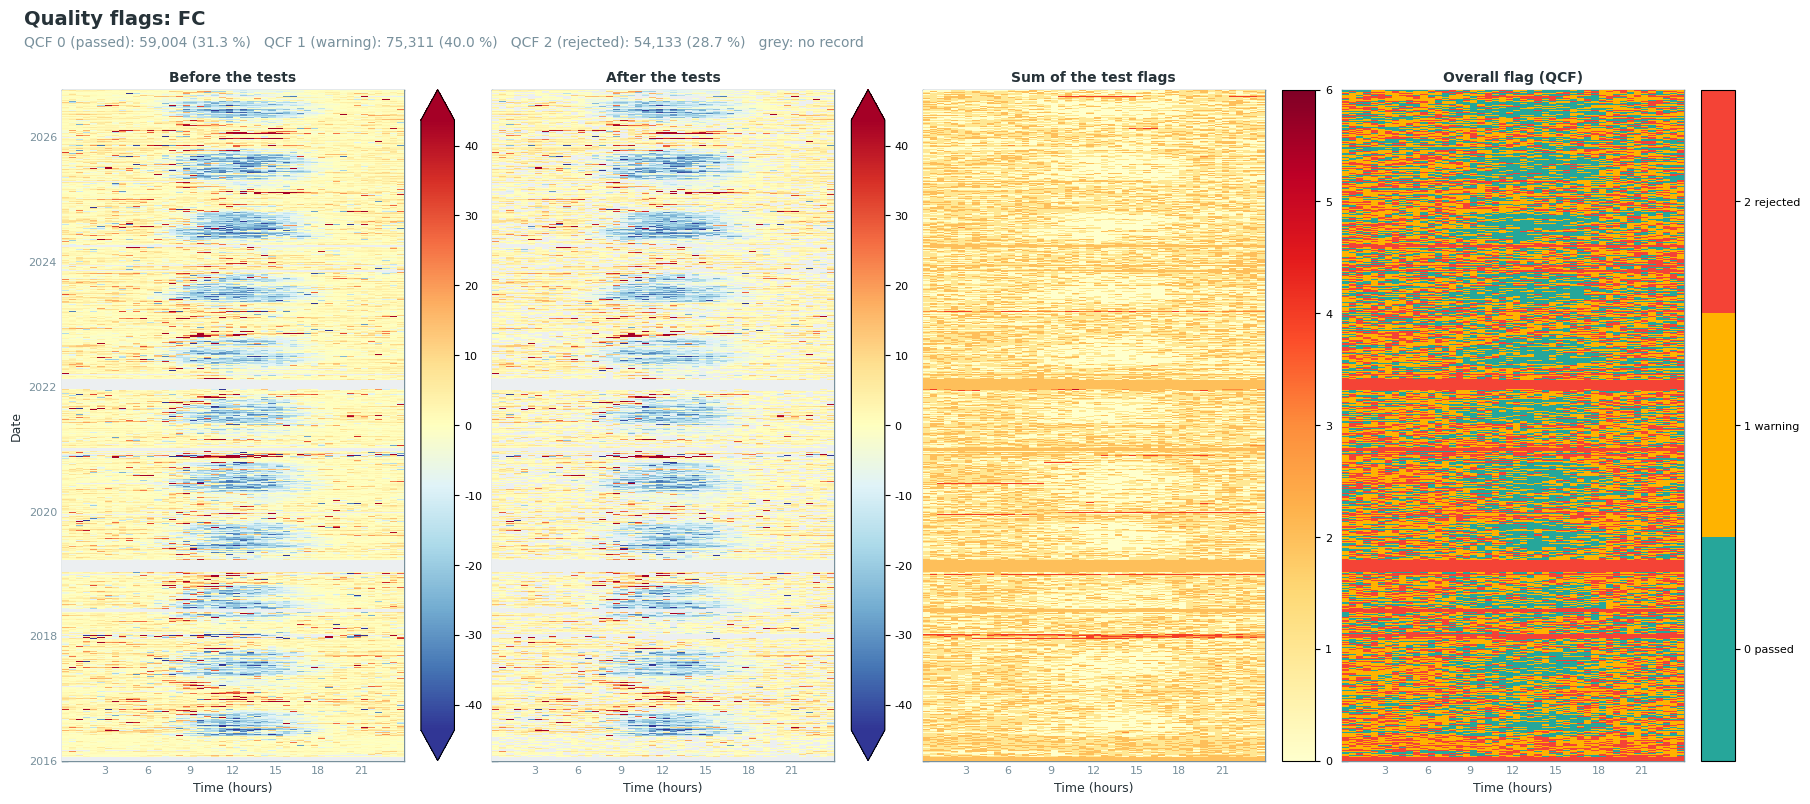

In [6]:
data.levels.level2_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-2 test

In [7]:
data.levels.level2_qcf.report_qcf_flags()

Test flags: FC
Measured records: 174,863 of 188,448
Missing records: 13,585 (7.21 %), flagged by the missing-values test
                                                  Pass     Warn     Fail    Fail      Not
Test                        Period    Tested       (0)      (1)      (2)       %   tested
─────────────────────────────────────────────────────────────────────────────────────────
L2_FC_SSITC                 all      174,863    59,224   75,971   39,668   22.69        0
                            day       88,760    36,411   35,941   16,408   18.49        0
                            night     86,103    22,813   40,030   23,260   27.01        0
                                                                                         
L2_FC_SCF                   all      174,863   174,631      193       39    0.02        0
                            day       88,760    88,663       82       15    0.02        0
                            night     86,103    85,968      111       24    0.03        0
                                                                                         
L2_FC_SIGNAL_STRENGTH       all      174,863   173,593        0    1,270    0.73        0
                            day       88,760    88,273        0      487    0.55        0
                            night     86,103    85,320        0      783    0.91        0
                                                                                         
L2_FC_CO2_VM97_SPIKE_HF     all      174,863   174,830        0       33    0.02        0
                            day       88,760    88,754        0        6   <0.01        0
                            night     86,103    86,076        0       27    0.03        0
                                                                                         
L2_FC_CO2_VM97_DROPOUT_HF   all      174,863   174,863        0        0    0.00        0
                            day       88,760    88,760        0        0    0.00        0
                            night     86,103    86,103        0        0    0.00        0

## Step 3: storage term (Level 3.1)

Adds the storage term to the flux (`FC + SC_SINGLE`). The storage term is the change in CO2
concentration at a single point, so it is only as good as the concentration, and it is screened in
two steps before it is added.

First, the storage term is discarded next to gaps in the concentration. After a signal loss the
LI-7200 can restart with readings far from the real concentration, for example 695 ppm on
21 December 2017, and return to it over several hours. Before a signal loss it can drift away in the
same way. The return or the drift is counted as a large storage flux of one sign, while the jump
across the gap is never counted, because the storage term needs the concentration of two
consecutive records. Over 2016 to 2026 these one-sided changes added up to about −150 gC m-2. A
record next to a gap counts as normal when its concentration lies within 3 robust standard deviations
of the median concentration at the same time of day over 7 days on either side. After a gap, the
storage values up to and including the first normal record are discarded; before a gap, the records
outside that band.

Second, isolated spikes are removed. A spike would make a good flux record an outlier, and Level 3.2
would remove the record. Spikes are found with a Hampel filter on the double differences of the
storage term (13 days, 5.5 sigma, one pass). A run of more than three flagged values in a row is
kept as measured: such a run is a noisy period, not a spike. Each spike run, together with one
record on either side, is replaced by the mean of its measured values. The sum over such a block is
the real concentration change across it, so the storage term stays balanced, and a single spike is
spread over three records.

The discarded values and the gaps in the storage term are filled with a rolling median, so every
measured flux keeps a storage term.

In [8]:
data = run_level31(data, gapfill_storage_term=True, set_storage_to_zero=False,
                   screen_storage_term=True, concentration_col=CO2_CONC)
print(f'After L3.1: {data.filteredseries.dropna().count():,} valid records '
      f'(col: {data.filteredseries.name})')

────────────────────────────────── Level 3.1: Storage Correction ───────────────────────────────────

> Calculating storage-corrected flux NEE_L3.1 from flux FC + storage term SC_SINGLE

> Storage term SC_SINGLE: 4,630 spike(s) found (2.66 % of the measured storage values)

> Storage term SC_SINGLE: 10,135 value(s) replaced by the mean of their block (spikes and one 
record on either side)

After L3.1: 134,315 valid records (col: NEE_L3.1_QCF)


### 📊 Plot: storage term screening

Checks that the screened and filled storage term still behaves like a storage term. The mean daily
cycle should stay positive at night and dip in the morning, when the CO2 that built up overnight is
released. The spikes should spread over the day with both signs; a cluster of negative spikes in the
morning would mean that real release was replaced. Over a year the storage term should sum to about
zero, and the gap between the two cumulative lines is the effect of the screening on the sum of the
flux. What remains of the drift lies in December 2017 and January 2018 and in November 2020, when
the analyser was failing. The fluxes of these periods are rejected by the signal strength test and
the periods removed by hand, so their storage term does not enter the flux.

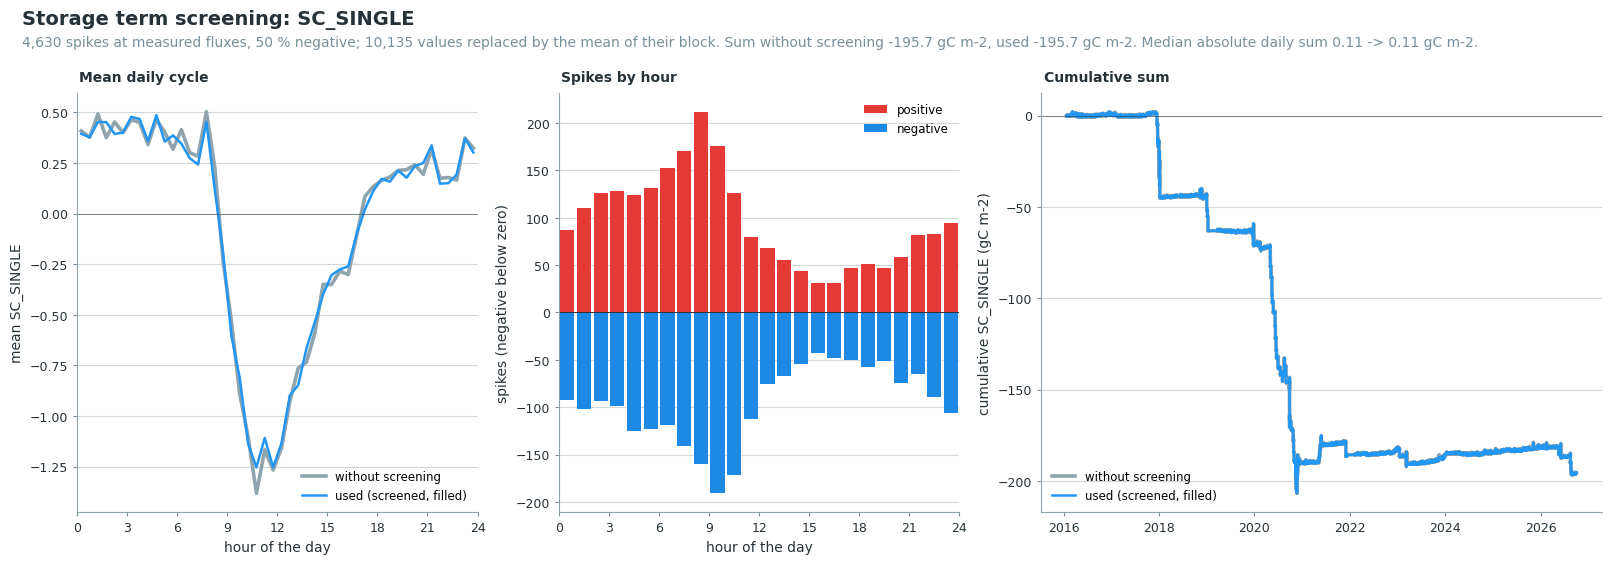

In [9]:
data.levels.level31.plot_screening(gain=UMOL_TO_GC, units='gC m-2');

## Step 4: outlier removal (Level 3.2)

Five tests:

1. Remove the periods in `REMOVE_DATES` by hand, see *Data sources*. Skipped when the processed years
   do not include them.
2. Absolute limits: remove values outside `ABSLIM`, ±50 µmol m-2 s-1, as in the 2016-2024
   notebooks. They catch extreme values in periods that the Hampel filters cannot judge, because
   the bad values fill their window.
3. Hampel filter on the double differences of neighbouring records. It finds single spikes.
4. Hampel filter on the values per time of day. Each record is compared with the records of the
   same half-hour, and of the half-hours before and after it, over 13 days. It finds values that
   are wrong for their time of day, such as noon-like uptake at sunrise, and runs of high values
   that the double differences do not catch.
5. Remove nighttime values clearly below zero, see *Negative values at night* below.

Both Hampel filters use 5.5 sigma by day and by night, over 13 days.

Each test first draws its plot. Check the plot, then run the cell below it, `sod.addflag()`, to
accept the test. A test that is not accepted removes nothing.

diive has more outlier tests. The table at the end of this step lists them. To add one, call its
method on `sod` in a new cell before *Apply the Level-3.2 flags*, check its plot, and accept it with
`sod.addflag()` in the cell after it.

In [10]:
data, sod = make_level32_detector(data)

### 📊 Plot: periods removed by hand

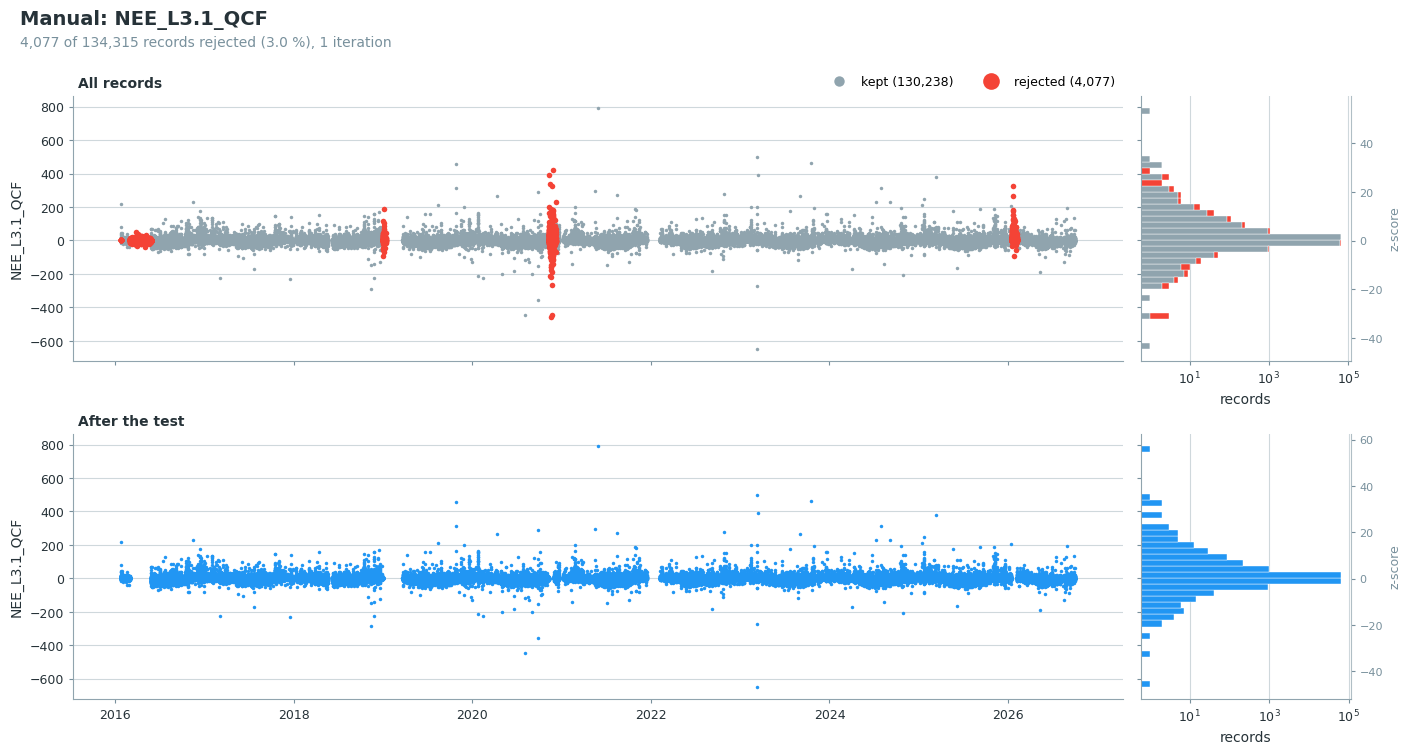

In [11]:
# Only the date ranges that overlap the processed records; none means no test and no flag.
_first, _last = data.full_df.index[0], data.full_df.index[-1]
_remove = [_d for _d in REMOVE_DATES
           if pd.Timestamp(_d[0]) <= _last and pd.Timestamp(_d[1]) + pd.Timedelta('1D') > _first]
if _remove:
    sod.flag_manualremoval_test(remove_dates=_remove, showplot=True, verbose=True)
else:
    print(f"No manual removal dates in {_first:%Y-%m-%d} - {_last:%Y-%m-%d}; test skipped.")

In [12]:
if _remove:
    sod.addflag()  # accept the manual removal

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_MANUAL_TEST to flag data

### 📊 Plot: absolute limits

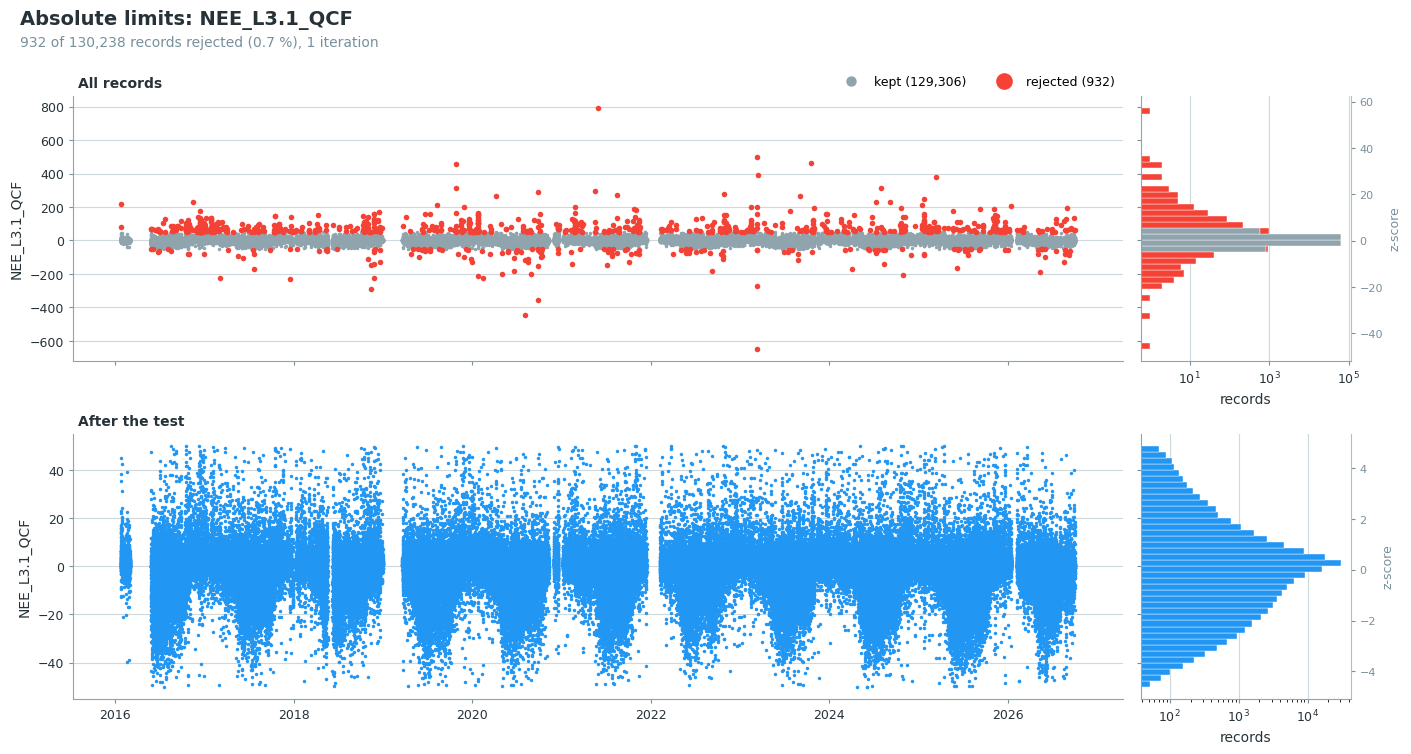

In [13]:
sod.flag_outliers_abslim_test(minval=ABSLIM[0], maxval=ABSLIM[1], showplot=True, verbose=True)

In [14]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_ABSLIM_TEST to flag data

### 📊 Plot: Hampel filter on double differences

[Dt/Nt] ITER #01 | Outliers:  2560 (  1.98%) | Day:  1084 | Night:  1476

[Dt/Nt] ITER #02 | Outliers:   315 (  0.25%) | Day:   112 | Night:   203

[Dt/Nt] ITER #03 | Outliers:    72 (  0.06%) | Day:    30 | Night:    42

[Dt/Nt] ITER #04 | Outliers:    13 (  0.01%) | Day:     7 | Night:     6

[Dt/Nt] ITER #05 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

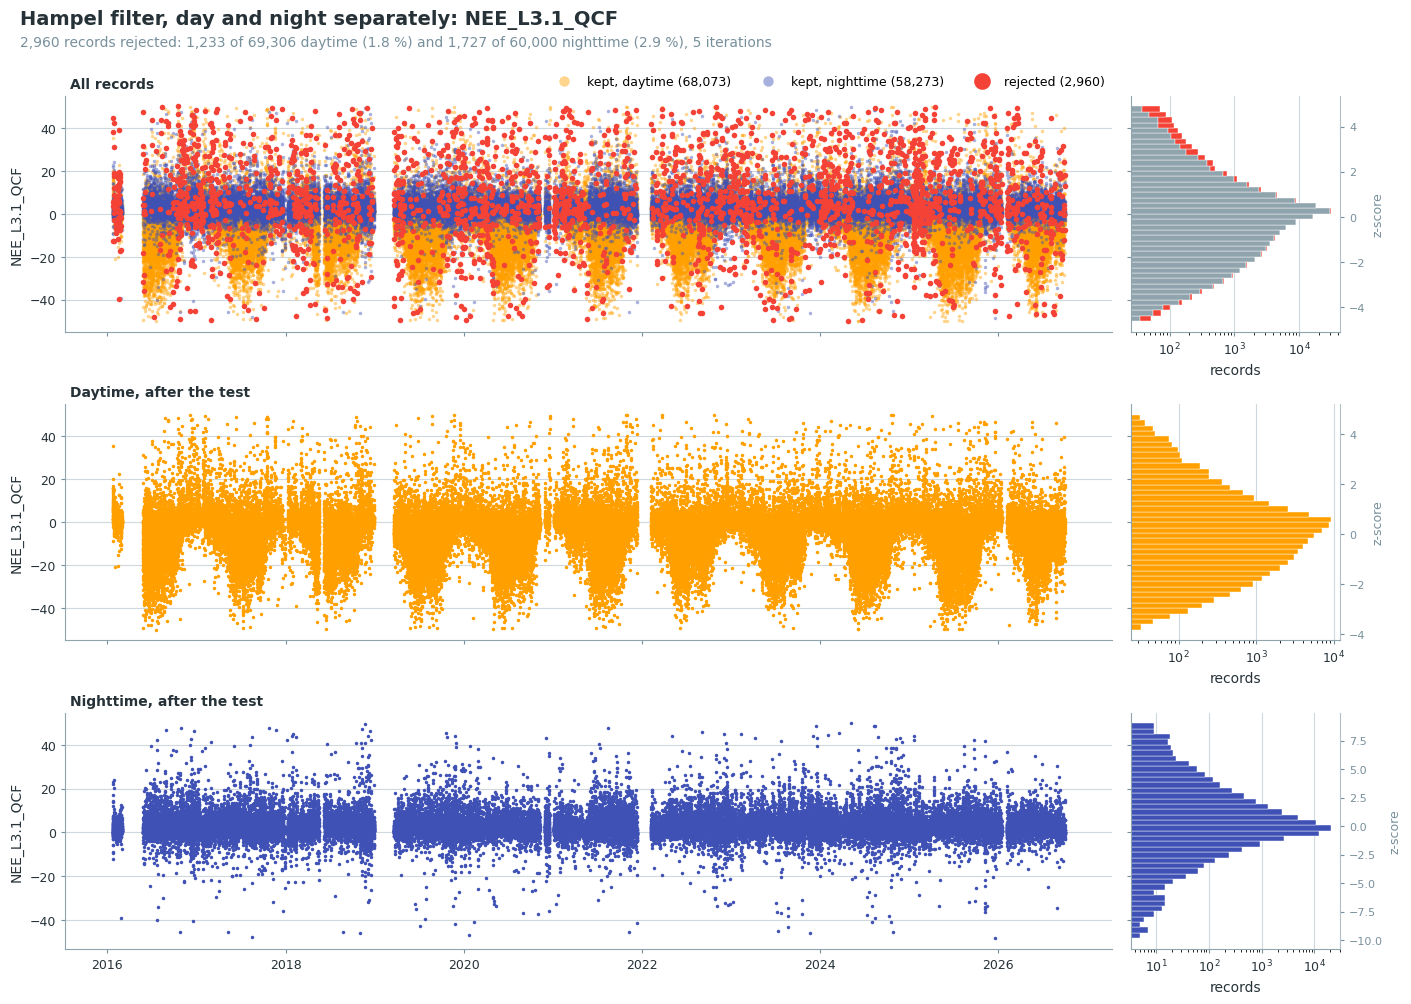

In [15]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=True,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [16]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_TEST to flag data

### 📊 Plot: Hampel filter on values per time of day

[Dt/Nt] ITER #01 | Outliers:  2071 (  1.64%) | Day:   867 | Night:  1204

[Dt/Nt] ITER #02 | Outliers:   259 (  0.21%) | Day:   114 | Night:   145

[Dt/Nt] ITER #03 | Outliers:    28 (  0.02%) | Day:    14 | Night:    14

[Dt/Nt] ITER #04 | Outliers:     4 (  0.00%) | Day:     1 | Night:     3

[Dt/Nt] ITER #05 | Outliers:     3 (  0.00%) | Day:     0 | Night:     3

[Dt/Nt] ITER #06 | Outliers:     2 (  0.00%) | Day:     0 | Night:     2

[Dt/Nt] ITER #07 | Outliers:     2 (  0.00%) | Day:     0 | Night:     2

[Dt/Nt] ITER #08 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

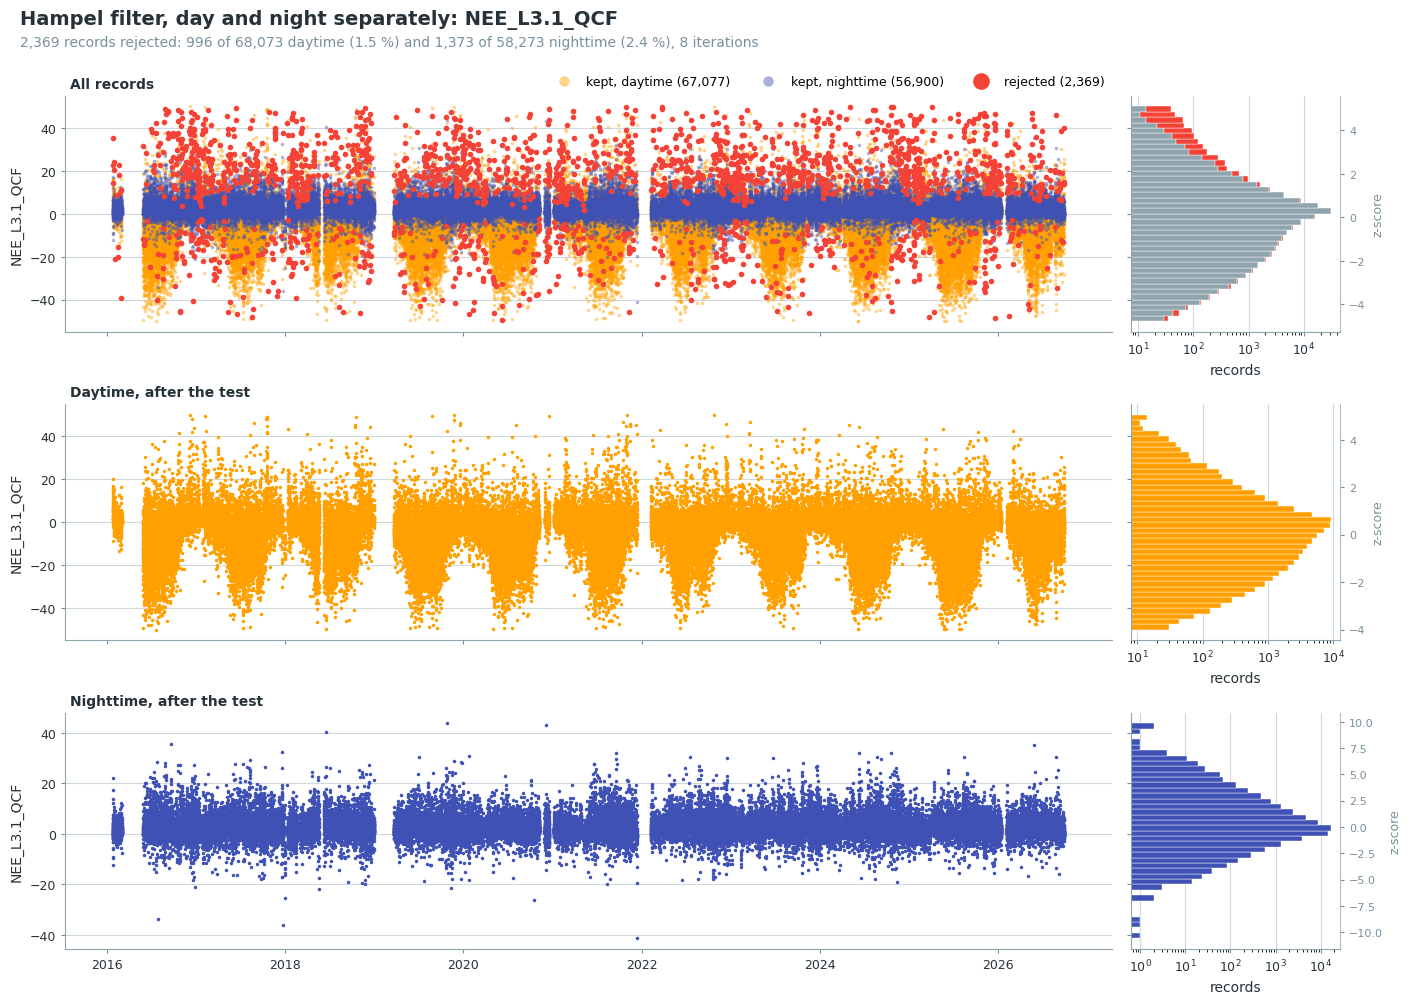

In [17]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=False,
                              by_time_of_day=True, time_of_day_slots=1, min_records=10,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [18]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_2_TEST to flag data

### Negative values at night

At night there is no photosynthesis, so the flux is respiration and its true value is zero or above.
A measured value can still be negative: random noise around a small respiration pushes some records
below zero. Such a value is plausible if it lies within a few times its random uncertainty (sigma)
of zero. A value below `-NIGHT_Z * sigma` is not, and test 4 removes it. Daytime values are not
tested, because by day both signs are real.

Removing every negative value would cut off one side of the noise and raise the nighttime flux. The
test therefore removes only the values that noise cannot explain. Its plot reports how many of the
removed records noise alone would have produced. If that number is small, the test removes errors,
not noise.

Sigma is the larger of two uncertainties for each record:

- **FS**: the uncertainty EddyPro gives for each half-hour (`FC_RANDUNC_HF`). It covers only the
  sampling error of that half-hour's covariance, so it is small.
- **PAS20**: the random uncertainty of FLUXNET2015 and ONEFlux, the spread of measured fluxes under
  similar conditions within days of each record. It also holds real differences between the
  fluxes, so it is a generous estimate of the random error. It is computed from the records the
  Hampel filters kept, so that outliers do not widen it.

With the larger of the two, a value counts as clearly below zero only if neither explains it.

### 📋 Table: random uncertainty of the nighttime records

In [19]:
sigma = nighttime_uncertainty(data, sod, randunc_col=RANDUNC_COL, ta=TA_F, vpd=VPD_F, swin=SW_IN_F)

Random uncertainty of the 56,900 nighttime records
uncertainty   median at night   below -2 sigma   below -3 sigma
───────────────────────────────────────────────────────────────
FS                       0.77    5,186 (9.1 %)    3,617 (6.4 %)
PAS20                    3.32      375 (0.7 %)       27 (0.0 %)
MAX                      3.34      329 (0.6 %)       21 (0.0 %)
FS: EddyPro, sampling error of each half-hour. PAS20: spread of similar measurements (ONEFlux), a 
generous estimate. MAX: the larger of the two.

### 📊 Plot: nighttime values clearly below zero

> Nighttime records below -3 uncertainties: 21. Expected from noise alone (Gaussian): 10.7 
records, raising the sum by 182.20 (flux units x records) once their gaps are filled.

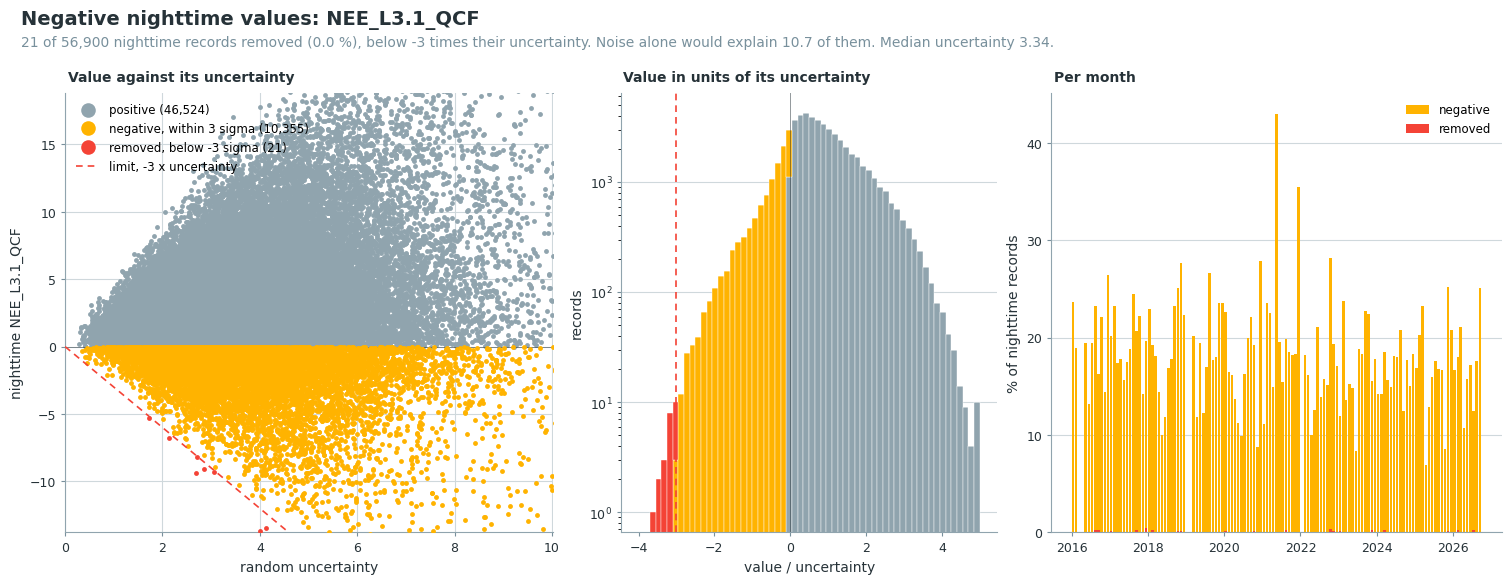

In [20]:
sod.flag_outliers_negative_night_test(uncertainty=sigma['MAX'], z=NIGHT_Z, showplot=True, verbose=True)

In [21]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_NEGNIGHT_TEST to flag data

### 📋 Table: outlier tests available in diive

Every test of the outlier detector `sod`, with the ones used above marked. `help(sod.<method>)`
shows the settings of a test.

In [22]:
_used = {'flag_manualremoval_test', 'flag_outliers_abslim_test', 'flag_outliers_hampel_test',
         'flag_outliers_negative_night_test'}
_rows = []
for _name in sorted(dir(type(sod))):
    if not (_name.startswith('flag_') and _name.endswith('_test')):
        continue
    # The first sentence of the docstring, which may run over two lines.
    _doc = (getattr(type(sod), _name).__doc__ or '').strip().split('\n\n')[0]
    _first = ' '.join(_doc.split()).split('. ')[0].rstrip('.')
    _rows.append({'method': f'sod.{_name}()', 'what it does': _first,
                  'used here': 'yes' if _name in _used else ''})
display(pd.DataFrame(_rows).set_index('method'))

,what it does,used here
method,,
sod.flag_manualremoval_test(),Flag specified records for removal,yes
sod.flag_missingvals_test(),Flag missing records in the data (flag 2 where...,
sod.flag_outliers_abslim_test(),Identify outliers based on absolute limits,yes
sod.flag_outliers_hampel_test(),Identify outliers in a sliding window based on...,yes
sod.flag_outliers_increments_zcore_test(),Identify outliers based on the z-score of reco...,
sod.flag_outliers_localsd_test(),Identify outliers based on standard deviation ...,
sod.flag_outliers_lof_test(),Local outlier factor detection (global or sepa...,
sod.flag_outliers_negative_night_test(),Flag nighttime values below -z times their ran...,yes
sod.flag_outliers_trim_low_test(),Flag values below a given absolute limit as ou...,


### Apply the Level-3.2 flags

In [23]:
data = run_level32(data, outlier_detector=sod)
print(f'After L3.2: {data.filteredseries.dropna().count():,} valid records')

────────────────────────────── Level 3.2: Stepwise Outlier Detection ───────────────────────────────

After L3.2: 123,956 valid records


### 📊 Plot: all removed outliers

Every record Level 3.2 removed, coloured by the test that removed it, with the share removed per
month and per hour of the day.

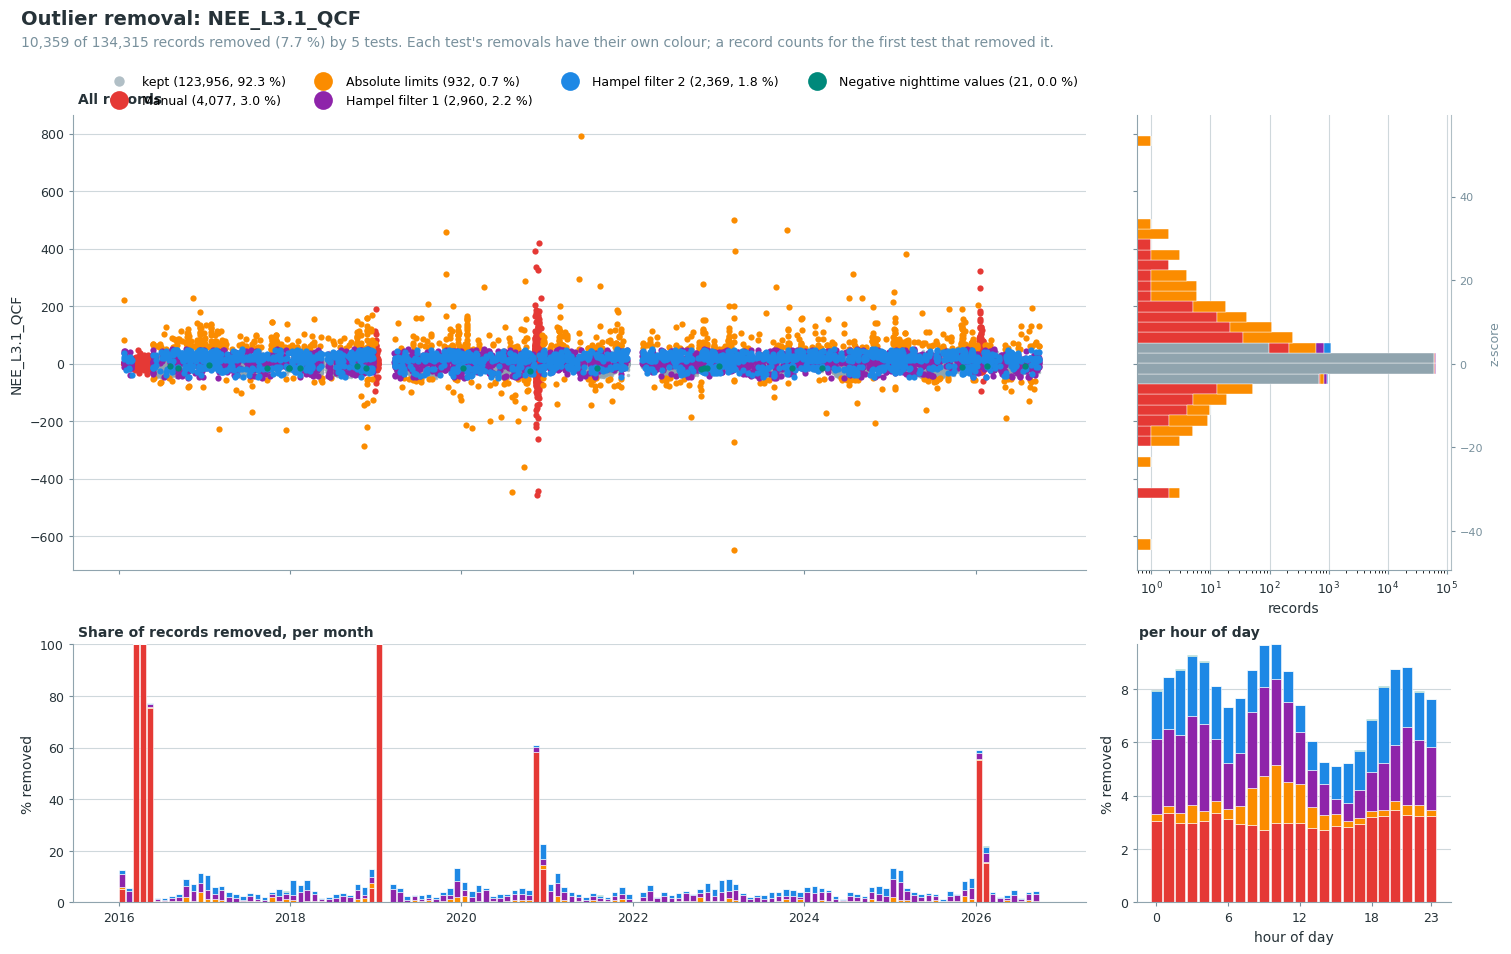

In [24]:
data.levels.level32.showplot_overview();

### 📊 Plot: Level-3.2 quality flag over time

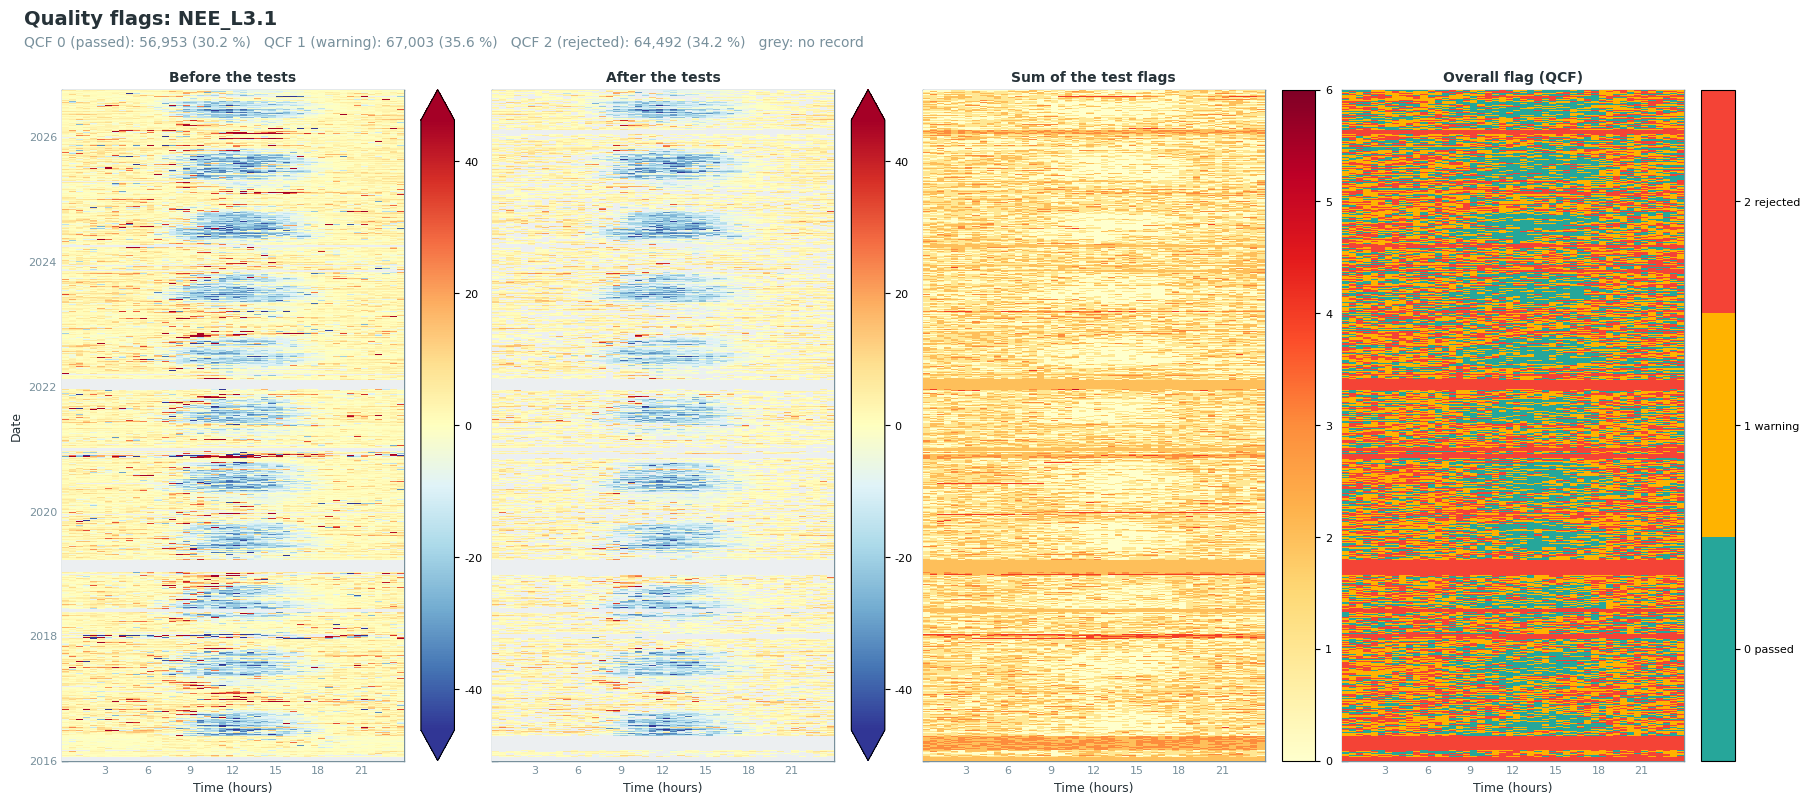

In [25]:
data.levels.level32_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-3.2 test

In [26]:
data.levels.level32_qcf.report_qcf_flags()

Test flags: NEE_L3.1
Measured records: 174,863 of 188,448
Missing records: 13,585 (7.21 %), flagged by the missing-values test
                                                           Pass     Warn     Fail    Fail      Not
Test                                 Period    Tested       (0)      (1)      (2)       %   tested
──────────────────────────────────────────────────────────────────────────────────────────────────
L2_FC_SSITC                          all      174,863    59,224   75,971   39,668   22.69        0
                                     day       88,760    36,411   35,941   16,408   18.49        0
                                     night     86,103    22,813   40,030   23,260   27.01        0
                                                                                                  
L2_FC_SCF                            all      174,863   174,631      193       39    0.02        0
                                     day       88,760    88,663       82       15    0.02        0
                                     night     86,103    85,968      111       24    0.03        0
                                                                                                  
L2_FC_SIGNAL_STRENGTH                all      174,863   173,593        0    1,270    0.73        0
                                     day       88,760    88,273        0      487    0.55        0
                                     night     86,103    85,320        0      783    0.91        0
                                                                                                  
L2_FC_CO2_VM97_SPIKE_HF              all      174,863   174,830        0       33    0.02        0
                                     day       88,760    88,754        0        6   <0.01        0
                                     night     86,103    86,076        0       27    0.03        0
                                                                                                  
L2_FC_CO2_VM97_DROPOUT_HF            all      174,863   174,863        0        0    0.00        0
                                     day       88,760    88,760        0        0    0.00        0
                                     night     86,103    86,103        0        0    0.00        0
                                                                                                  
L3.2_NEE_L3.1_QCF_OUTLIER_MANUAL     all      134,315   130,238        0    4,077    3.04   40,548
                                     day       72,015    70,015        0    2,000    2.78   16,745
                                     night     62,300    60,223        0    2,077    3.33   23,803
                                                                                                  
L3.2_NEE_L3.1_QCF_OUTLIER_ABSLIM     all      130,238   129,306        0      932    0.72   44,625
                                     day       70,015    69,306        0      709    1.01   18,745
                                     night     60,223    60,000        0      223    0.37   25,880
                                                                                                  
L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL     all      129,306   126,346        0    2,960    2.29   45,557
                                     day       69,306    68,073        0    1,233    1.78   19,454
                                     night     60,000    58,273        0    1,727    2.88   26,103
                                                                                                  
L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_2   all      126,346   123,977        0    2,369    1.88   48,517
                                     day       68,073    67,077        0      996    1.46   20,687
                                     night     58,273    56,900        0    1,373    2.36   27,830
                                                                                                  
L3.2_NEE_L3.

## Step 5: USTAR filter (Level 3.3)

Removes records with weak turbulence, where the friction velocity (USTAR) is below a threshold, by
day and by night, as ONEFlux does. Unlike ONEFlux, the first record above the threshold after a
period below it is kept. Records without USTAR are removed too. There are three scenarios,
one per threshold: the 16th, 50th and 84th percentile of the threshold detection on the 2016-2024
record. These fixed thresholds are used for the whole record. From here on each scenario has its own
series, so `data.filteredseries` is empty.

In [27]:
data = run_level33_constant_ustar(
    data,
    thresholds=USTAR_THRESHOLDS,
    threshold_labels=USTAR_SCENARIOS,
    showplot=False,
    verbose=True,
)

──────────────────────────────────── Level 3.3: USTAR Filtering ────────────────────────────────────

> QCF computed for USTAR scenario CUT_16

> QCF computed for USTAR scenario CUT_50

> QCF computed for USTAR scenario CUT_84

### Records for gap-filling and highest-quality records

After Level 3.3 every measured record that failed a test or the USTAR filter is removed. What is
left depends on two settings: the USTAR scenario, and the quality flags that are accepted
(`DAYTIME_ACCEPT_QCF_BELOW` and `NIGHTTIME_ACCEPT_QCF_BELOW`, here 2, so QCF 0 and 1). These records
are what the gap-filling starts from.

The highest-quality records (QCF 0) passed every test without a warning. Use them for analyses that
need measured values only, without gap-filled ones. The output file holds them in one column per
scenario, ending in `_L3.3_<scenario>_QCF0`; the records for gap-filling end in `_L3.3_<scenario>_QCF`.

### 📋 Table: records per USTAR scenario

In [28]:
report_gapfilling_input(data);

Records for gap-filling
                    removed:   removed:             used:    used:    used:    used:
USTAR    measured      tests      USTAR     used    QCF 0    QCF 1      day    night
────────────────────────────────────────────────────────────────────────────────────
CUT_16    174,863     50,907     31,492   92,464   49,077   43,387   55,012   37,452
              93%        27%        17%      49%      26%      23%      29%      20%
CUT_50    174,863     50,907     37,160   86,796   46,815   39,981   51,957   34,839
              93%        27%        20%      46%      25%      21%      28%      18%
CUT_84    174,863     50,907     43,676   80,280   44,035   36,245   48,391   31,889
              93%        27%        23%      43%      23%      19%      26%      17%
Records, and their share of all 188,448 records of the period.
removed: tests = quality tests and outlier detection (Levels 2 to 3.2).
used = records for gap-filling: QCF below 2 by day and below 2 by night. QCF 0 is the highest 
quality, the measured flux for analyses without gap-filled values.

### 📊 Plot: records for gap-filling and highest-quality records

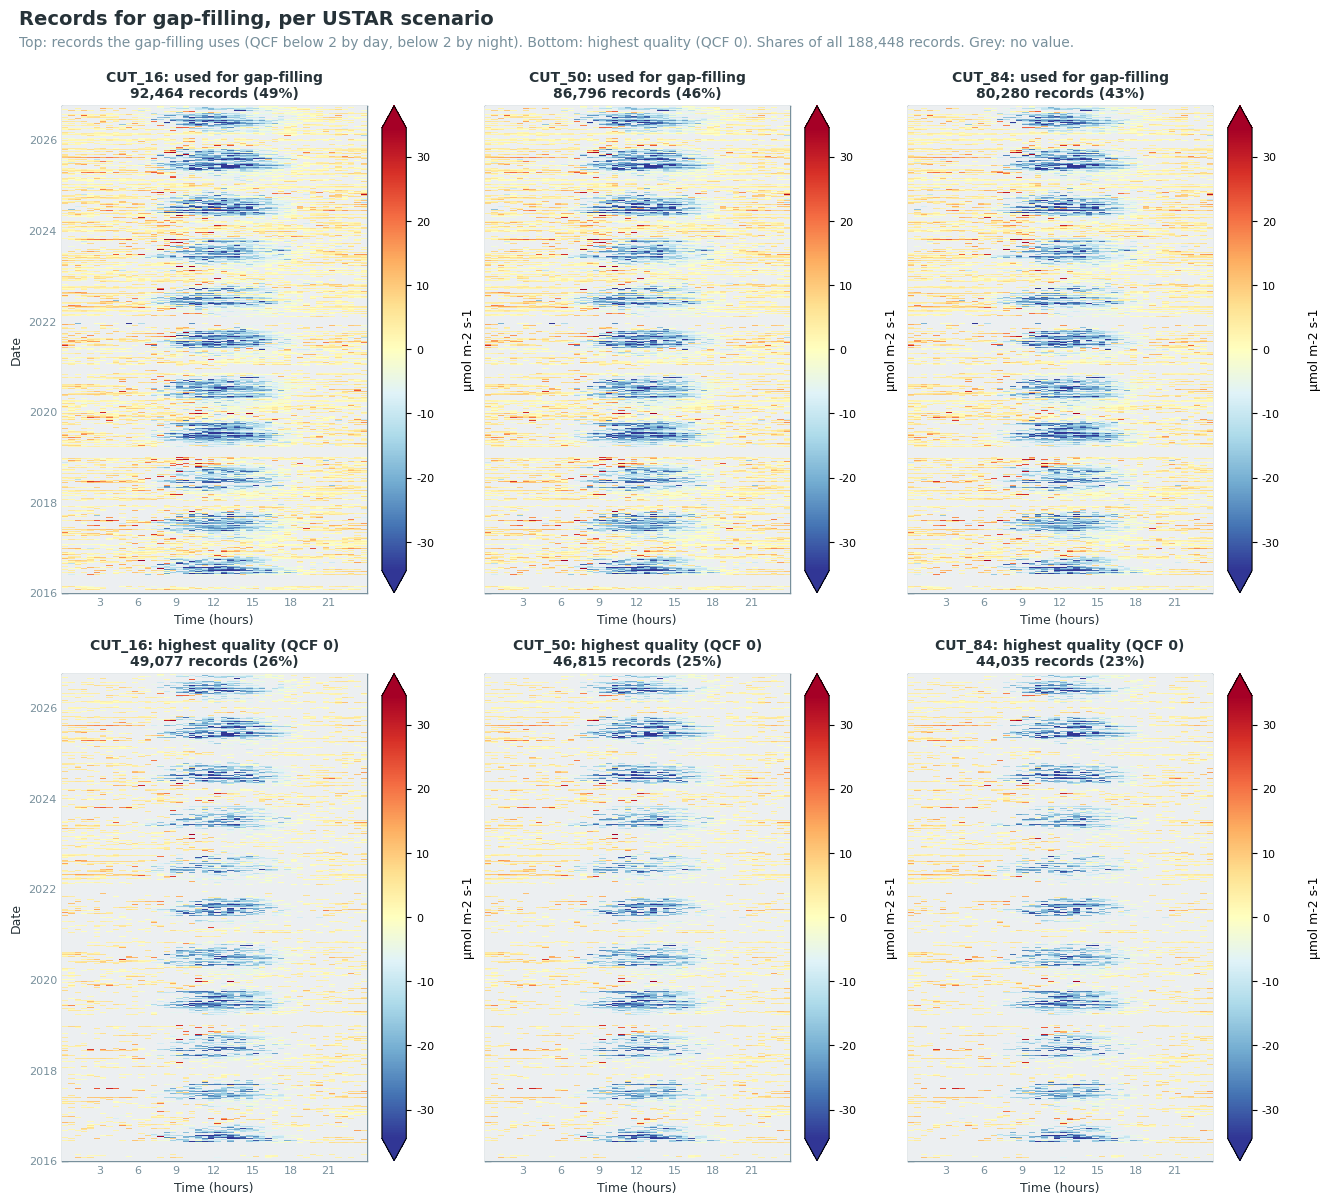

In [29]:
plot_gapfilling_input(data, units=FLUX_UNITS)

### 📋 Table: gaps per USTAR scenario

The gaps left after Level 3.3, which the gap-filling has to fill. A long gap lasts at least one day.

In [30]:
report_gaps(data, long_gap_days=1);

Gaps to fill
USTAR    missing %    gaps   long gaps   longest gap (days)   worst month   worst month missing %
─────────────────────────────────────────────────────────────────────────────────────────────────
CUT_16        50.9   23776          37                 86.0           Jan                    64.8
CUT_50        53.9   22903          46                 86.4           Dec                    66.8
CUT_84        57.4   21776          67                 86.4           Dec                    69.8
A long gap lasts at least 1 day.

## Step 6: meteo drivers and model features

The ONEFlux partitioning needs measured temperature and radiation. These are the complete driver
series, restricted to the records measured at 47 m. `add_driver` puts them into `data.full_df`,
where Levels 4.1 and 4.2 look for their drivers.

The feature engineer adds lagged values, rolling statistics and time terms to the drivers. It is
built once and passed to XGBoost. `target_col` is only a placeholder.

In [31]:
_ta_meas = df[TA_F].where(df[TA_FLAG] == 0).rename(TA_MEAS)
_sw_meas = df[SW_IN_F].where(df[SW_IN_FLAG] == 0).rename(SW_IN_MEAS)
data = add_driver(data, _ta_meas)
data = add_driver(data, _sw_meas)
print(f"{TA_MEAS}: {_ta_meas.notna().sum():,} measured records of {len(_ta_meas):,}")
print(f"{SW_IN_MEAS}: {_sw_meas.notna().sum():,} measured records of {len(_sw_meas):,}")

engineer = FeatureEngineer(
    target_col='_target_',
    features_lag=[-2, 2],
    features_lag_stepsize=1,
    features_rolling=[2, 4, 12, 24, 48],
    features_rolling_stats=['median', 'min', 'max', 'std'],
    features_ema=[6, 12, 24, 48],
    vectorize_timestamps=True,
    add_continuous_record_number=True,
    sanitize_timestamp=True,
    verbose=0,
)

TA_T1_47_1_HOMOGENIZED_MEASURED: 186,575 measured records of 188,448
SW_IN_T1_47_1_MEASURED: 186,603 measured records of 188,448


## Step 7: gap-filling (Level 4.1)

Two methods fill the gaps of each USTAR scenario: XGBoost, the method of this dataset, and MDS,
the standard method of FLUXNET, for comparison. Step 11 compares the two.

### XGBoost

Each year gets its own model for each USTAR scenario, trained on that year and its two neighbouring
years. SHAP values select the features: a feature is kept if it is clearly more important than a
random variable. Every scenario then uses the features that any scenario selected, so the scenarios
differ in their records, not in their features.

In [32]:
data = run_level41_xgb(
    data,
    features=FEATURES,
    engineer=engineer,
    reduce_features=True,
    verbose=1,
    **XGB_SETTINGS,
)

───────────────────────────────── Level 4.1: Gap-Filling (XGBoost) ─────────────────────────────────

### MDS

Marginal distribution sampling (Reichstein et al. 2005) fills each gap with the mean of measured
fluxes under similar conditions: incoming radiation, air temperature and VPD within set
tolerances, in a time window that widens until enough similar records are found. `mode='diive'`
takes a symmetric mean by day (Vekuri et al. 2023) and fills every gap, also long ones, because
this dataset needs complete years. Only measured driver values serve as similar records (the
`ISFILLED` flags of the drivers). MDS predicts each measured record without using it, so its
scores are out-of-sample.

**Skipped** when `RUN_MDS = False`.

In [33]:
if RUN_MDS:
    data = run_level41_mds(
        data,
        swin=SW_IN_F, ta=TA_F, vpd=VPD_F,  # W m-2, degC, kPa
        swin_qc=SW_IN_FLAG, ta_qc=TA_FLAG, vpd_qc=VPD_FLAG,
        **MDS_SETTINGS,
    )

─────────────────────────────────── Level 4.1: Gap-Filling (MDS) ───────────────────────────────────

## Step 8: partitioning into GPP and RECO (Level 4.2)

**Not part of this version of the dataset** (`RUN_PARTITIONING = False`).

Splits the flux into GPP and RECO for each USTAR scenario, with both methods as ONEFlux implements
them (the code used by ICOS and FLUXNET). The nighttime method (Reichstein et al. 2005) fits the
temperature response of the nighttime flux. The daytime method (Lasslop et al. 2010) fits a light
response curve to the daytime flux. Both fit the measured flux and use the gap-filled flux of
Level 4.1 to compute GPP. Their output columns end in `_NT_OF` and `_DT_OF`. ONEFlux itself
partitions a flux filled with MDS, so these columns are not identical to ONEFlux output.

In [34]:
if RUN_PARTITIONING:
    data = run_level42_partitioning(
        data,
        method='nighttime',
        mode='oneflux',
        ta=TA_MEAS,
        sw_in=SW_IN_MEAS,
        ta_f=TA_F,
        gapfill_method='xgb',
    )

In [35]:
if RUN_PARTITIONING:
    data = run_level42_partitioning(
        data,
        method='daytime',
        mode='oneflux',
        ta=TA_MEAS,
        sw_in=SW_IN_MEAS,
        ta_f=TA_F,
        sw_in_f=SW_IN_F,
        vpd_f=VPD_F,  # kPa
        gapfill_method='xgb',
    )
    print(data.partitioned_cols())

## Step 9: results

How many records were measured and how many were filled, then the annual sum of the flux, for each
USTAR scenario. In 2016 about 108 days have no measurements (see the per-year plot below), so its
sum rests largely on the model. 2026 ends on 30 September.

### 📋 Table: measured and filled records

In [36]:
report_gapfilling_variables(data)

Gap-filled variables
method    USTAR    records   measured    filled   filled %
──────────────────────────────────────────────────────────
MDS       CUT_16   188,448     92,464    95,984       50.9
MDS       CUT_50   188,448     86,796   101,652       53.9
MDS       CUT_84   188,448     80,280   108,168       57.4
XGBoost   CUT_16   188,448     92,464    95,984       50.9
XGBoost   CUT_50   188,448     86,796   101,652       53.9
XGBoost   CUT_84   188,448     80,280   108,168       57.4
MDS (CUT_16): NEE_L3.1_L3.3_CUT_16_QCF -> NEE_L3.1_L3.3_CUT_16_QCF_gfMDS
MDS (CUT_50): NEE_L3.1_L3.3_CUT_50_QCF -> NEE_L3.1_L3.3_CUT_50_QCF_gfMDS
MDS (CUT_84): NEE_L3.1_L3.3_CUT_84_QCF -> NEE_L3.1_L3.3_CUT_84_QCF_gfMDS
XGBoost (CUT_16): NEE_L3.1_L3.3_CUT_16_QCF -> NEE_L3.1_L3.3_CUT_16_QCF_gfXG
XGBoost (CUT_50): NEE_L3.1_L3.3_CUT_50_QCF -> NEE_L3.1_L3.3_CUT_50_QCF_gfXG
XGBoost (CUT_84): NEE_L3.1_L3.3_CUT_84_QCF -> NEE_L3.1_L3.3_CUT_84_QCF_gfXG

### 📋 Table: annual sums of the flux

In [37]:
report_annual_sums(data, gain=UMOL_TO_GC, units='gC m-2');

Annual sums (gC m-2)
                MDS          MDS          MDS      XGBoost      XGBoost      XGBoost
year         CUT_16       CUT_50       CUT_84       CUT_16       CUT_50       CUT_84
────────────────────────────────────────────────────────────────────────────────────
2016     -314 (38%)   -290 (35%)   -244 (33%)   -167 (38%)   -139 (35%)   -106 (33%)
2017      -25 (52%)      9 (49%)     11 (45%)     40 (52%)     63 (49%)     86 (45%)
2018     -227 (48%)   -211 (46%)   -192 (42%)   -130 (48%)   -108 (46%)    -85 (42%)
2019     -324 (42%)   -318 (39%)   -318 (36%)   -276 (42%)   -272 (39%)   -261 (36%)
2020     -369 (49%)   -346 (46%)   -324 (43%)   -298 (49%)   -280 (46%)   -256 (43%)
2021     -105 (48%)   -107 (45%)    -89 (42%)    -50 (48%)    -26 (45%)     -9 (42%)
2022     -121 (50%)   -108 (47%)    -89 (43%)    -50 (50%)    -27 (47%)     -4 (43%)
2023      -37 (54%)    -20 (51%)      4 (47%)    -11 (54%)      9 (51%)     43 (47%)
2024      -72 (52%)    -48 (49%)    -22 (45%)    -50 (52%)    -29 (49%)    -10 (45%)
2025     -469 (55%)   -446 (51%)   -439 (47%)   -373 (55%)   -346 (51%)   -319 (47%)
2026 *   -363 (52%)   -350 (49%)   -326 (46%)   -312 (52%)   -294 (49%)   -262 (46%)
In brackets: the share of the year's records that were measured.
* Incomplete year (2026): the sum covers only part of it.

## Step 10: model quality

First the scores on test data: a random 25 % of the complete records, which the model did not see in
training. Early stopping uses a part of the training data, not the test data. Because the test
records lie between training records, the scores describe short gaps better than gaps of several
days.

### 📋 Table: scores on test data

In [38]:
report_traintest_model_scores(data)

Held-out test scores
method    USTAR    year      R²   RMSE    MAE   MedAE   MaxE
────────────────────────────────────────────────────────────
XGBoost   CUT_16   2016   0.699   5.67   3.77    2.43   47.7
XGBoost   CUT_16   2017   0.699   5.67   3.77    2.43   47.7
XGBoost   CUT_16   2018   0.706   5.60   3.72    2.40   48.0
XGBoost   CUT_16   2019   0.713   5.58   3.58    2.23   55.5
XGBoost   CUT_16   2020   0.726   5.52   3.62    2.29   42.8
XGBoost   CUT_16   2021   0.719   5.45   3.57    2.25   49.1
XGBoost   CUT_16   2022   0.710   5.42   3.51    2.19   43.6
XGBoost   CUT_16   2023   0.736   5.24   3.45    2.18   45.6
XGBoost   CUT_16   2024   0.768   5.12   3.35    2.11   45.1
XGBoost   CUT_16   2025   0.771   5.15   3.43    2.18   46.1
XGBoost   CUT_16   2026   0.771   5.15   3.43    2.18   46.1
XGBoost   CUT_16   mean   0.729   5.42   3.56    2.26   47.0
                                                            
XGBoost   CUT_50   2016   0.711   5.52   3.67    2.35   42.1
XGBoost   CUT_50   2017   0.711   5.52   3.67    2.35   42.1
XGBoost   CUT_50   2018   0.718   5.55   3.68    2.36   43.4
XGBoost   CUT_50   2019   0.747   5.26   3.51    2.27   45.5
XGBoost   CUT_50   2020   0.729   5.56   3.64    2.26   45.1
XGBoost   CUT_50   2021   0.732   5.38   3.49    2.17   43.7
XGBoost   CUT_50   2022   0.724   5.39   3.53    2.22   43.4
XGBoost   CUT_50   2023   0.753   5.11   3.37    2.18   44.5
XGBoost   CUT_50   2024   0.771   5.16   3.41    2.13   51.8
XGBoost   CUT_50   2025   0.766   5.31   3.46    2.16   46.7
XGBoost   CUT_50   2026   0.766   5.31   3.46    2.16   46.7
XGBoost   CUT_50   mean   0.739   5.37   3.54    2.24   45.0
                                                            
XGBoost   CUT_84   2016   0.706   5.69   3.74    2.36   41.1
XGBoost   CUT_84   2017   0.706   5.69   3.74    2.36   41.1
XGBoost   CUT_84   2018   0.730   5.50   3.62    2.35   49.6
XGBoost   CUT_84   2019   0.748   5.43   3.59    2.35   48.6
XGBoost   CUT_84   2020   0.740   5.52   3.64    2.29   45.6
XGBoost   CUT_84   2021   0.737   5.33   3.49    2.19   49.4
XGBoost   CUT_84   2022   0.712   5.61   3.61    2.23   44.1
XGBoost   CUT_84   2023   0.761   5.16   3.41    2.15   50.5
XGBoost   CUT_84   2024   0.781   5.10   3.40    2.22   47.6
XGBoost   CUT_84   2025   0.779   5.27   3.41    2.09   50.2
XGBoost   CUT_84   2026   0.779   5.27   3.41    2.09   50.2
XGBoost   CUT_84   mean   0.743   5.42   3.55    2.24   47.1
Test set: a random share of the complete records, not used in training.
Errors are in the units of the flux.
Not available for MDS (CUT_16), MDS (CUT_50), MDS (CUT_84).

### 📋 Table: gap-filling models per year

How each model was built and how well it did: the years it was trained on, its features, the
training and test records, the number of trees early stopping chose, the records of the final fit,
the test scores, and how the gaps of its year were filled.

In [39]:
report_model_overview(data);

Gap-filling models
                trained                                          final    test   te…            fal…
USTAR    year   on          features    train   test     trees     fit      R²   RM…   filled   back
────────────────────────────────────────────────────────────────────────────────────────────────────
CUT_16   2016   2016-2018        103   18,202   6,0…   188/350   24,2…   0.699   5.…   10,900      0
CUT_16   2017   2016-2018        103   18,202   6,0…   188/350   24,2…   0.699   5.…    8,393      0
CUT_16   2018   2017-2019        103   18,717   6,2…   127/350   24,9…   0.706   5.…    9,045      0
CUT_16   2019   2018-2020        103   18,324   6,1…   325/350   24,4…   0.713   5.…   10,165      0
CUT_16   2020   2019-2021        103   18,320   6,1…   129/350   24,4…   0.726   5.…    8,965      0
CUT_16   2021   2020-2022        103   19,328   6,4…   192/350   25,7…   0.719   5.…    9,051      0
CUT_16   2022   2021-2023        103   19,947   6,6…   272/350   26,5…   0.710   5.…    8,821      0
CUT_16   2023   2022-2024        103   20,511   6,8…   243/350   27,3…   0.736   5.…    8,091      0
CUT_16   2024   2023-2025        103   21,183   7,0…   174/350   28,2…   0.768   5.…    8,347      0
CUT_16   2025   2024-2026        103   19,229   6,4…   137/350   25,6…   0.771   5.…    7,926      0
CUT_16   2026   2024-2026        103   19,229   6,4…   137/350   25,6…   0.771   5.…    6,280      0
                                                                                                    
CUT_50   2016   2016-2018        103   17,064   5,6…   102/350   22,7…   0.711   5.…   11,349      0
CUT_50   2017   2016-2018        103   17,064   5,6…   102/350   22,7…   0.711   5.…    8,969      0
CUT_50   2018   2017-2019        103   17,568   5,8…   227/350   23,4…   0.718   5.…    9,537      0
CUT_50   2019   2018-2020        103   17,254   5,7…   175/350   23,0…   0.747   5.…   10,629      0
CUT_50   2020   2019-2021        103   17,211   5,7…   173/350   22,9…   0.729   5.…    9,436      0
CUT_50   2021   2020-2022        103   18,188   6,0…   315/350   24,2…   0.732   5.…    9,594      0
CUT_50   2022   2021-2023        103   18,769   6,2…   184/350   25,0…   0.724   5.…    9,327      0
CUT_50   2023   2022-2024        103   19,256   6,4…   346/350   25,6…   0.753   5.…    8,613      0
CUT_50   2024   2023-2025        103   19,841   6,6…   276/350   26,4…   0.771   5.…    8,993      0
CUT_50   2025   2024-2026        103   17,995   5,9…   158/350   23,9…   0.766   5.…    8,547      0
CUT_50   2026   2024-2026        103   17,995   5,9…   158/350   23,9…   0.766   5.…    6,658      0
                                                                                                    
CUT_84   2016   2016-2018        103   15,772   5,2…   115/350   21,0…   0.706   5.…   11,842      0
CUT_84   2017   2016-2018        103   15,772   5,2…   115/350   21,0…   0.706   5.…    9,644      0
CUT_84   2018   2017-2019        103   16,244   5,4…   226/350   21,6…   0.730   5.…   10,092      0
CUT_84   2019   2018-2020        103   16,008   5,3…   285/350   21,3…   0.748   5.…   11,165      0
CUT_84   2020   2019-2021        103   15,906   5,3…   267/350   21,2…   0.740   5.…   10,006      0
CUT_84   2021   2020-2022        103   16,851   5,6…   166/350   22,4…   0.737   5.…   10,229      0
CUT_84   2022   2021-2023        103   17,388   5,7…    91/350   23,1…   0.712   5.…    9,904      0
CUT_84   2023   2022-2024        103   17,814   5,9…   220/350   23,7…   0.761   5.…    9,243      0
CUT_84   2024   2023-2025        103   18,303   6,1…   141/350   24,4…   0.781   5.…    9,709      0
CUT_84   2025   2024-2026        103   16,611   5,5…   292/350   22,1…   0.779   5.…    9,251      0
CUT_84   2026   2024-2026        103   16,611   5,5…   292/350   22,1…   0.779   5.…    7,083      0
Each year has its own model, trained on that year and its neighbours ('trained on').
train / test: a random 75 / 25 % split of the complete rec

Next the scores on all measured records. The gaps are filled by a model refitted on all of them, so
these scores are better than the test scores and only show how closely the model fits.

### 📋 Table: scores on all measured records

In [40]:
report_gapfilling_model_scores(data)

In-sample scores
method    USTAR    year      R²   RMSE    MAE   MedAE   MaxE
────────────────────────────────────────────────────────────
MDS       CUT_16   all    0.634   6.33   4.14    2.59   70.6
MDS       CUT_50   all    0.644   6.31   4.14    2.60   67.6
MDS       CUT_84   all    0.658   6.27   4.13    2.61   59.4
XGBoost   CUT_16   2016   0.806   4.56   3.12    2.07   34.3
XGBoost   CUT_16   2017   0.806   4.56   3.12    2.07   34.3
XGBoost   CUT_16   2018   0.783   4.82   3.29    2.21   37.3
XGBoost   CUT_16   2019   0.847   4.07   2.80    1.90   29.0
XGBoost   CUT_16   2020   0.798   4.80   3.24    2.12   40.5
XGBoost   CUT_16   2021   0.812   4.44   2.99    1.93   38.8
XGBoost   CUT_16   2022   0.833   4.16   2.85    1.90   34.9
XGBoost   CUT_16   2023   0.837   4.12   2.84    1.92   34.8
XGBoost   CUT_16   2024   0.832   4.35   2.95    1.93   35.9
XGBoost   CUT_16   2025   0.834   4.34   2.95    1.94   38.9
XGBoost   CUT_16   2026   0.834   4.34   2.95    1.94   38.9
XGBoost   CUT_16   mean   0.820   4.41   3.01    1.99   36.1
                                                            
XGBoost   CUT_50   2016   0.783   4.89   3.33    2.19   39.6
XGBoost   CUT_50   2017   0.783   4.89   3.33    2.19   39.6
XGBoost   CUT_50   2018   0.821   4.42   3.05    2.09   31.2
XGBoost   CUT_50   2019   0.821   4.43   3.03    2.02   34.7
XGBoost   CUT_50   2020   0.817   4.61   3.12    2.05   39.3
XGBoost   CUT_50   2021   0.849   4.01   2.75    1.83   31.4
XGBoost   CUT_50   2022   0.816   4.40   2.99    1.96   36.7
XGBoost   CUT_50   2023   0.864   3.81   2.64    1.80   32.0
XGBoost   CUT_50   2024   0.861   4.00   2.74    1.83   32.7
XGBoost   CUT_50   2025   0.846   4.23   2.89    1.90   37.6
XGBoost   CUT_50   2026   0.846   4.23   2.89    1.90   37.6
XGBoost   CUT_50   mean   0.828   4.36   2.98    1.98   35.7
                                                            
XGBoost   CUT_84   2016   0.798   4.77   3.27    2.16   38.8
XGBoost   CUT_84   2017   0.798   4.77   3.27    2.16   38.8
XGBoost   CUT_84   2018   0.832   4.33   3.00    2.05   32.5
XGBoost   CUT_84   2019   0.852   4.06   2.81    1.93   29.4
XGBoost   CUT_84   2020   0.849   4.22   2.91    1.94   34.4
XGBoost   CUT_84   2021   0.820   4.43   3.00    1.96   36.6
XGBoost   CUT_84   2022   0.790   4.77   3.20    2.06   42.6
XGBoost   CUT_84   2023   0.849   4.06   2.81    1.91   35.1
XGBoost   CUT_84   2024   0.842   4.34   2.96    1.96   36.2
XGBoost   CUT_84   2025   0.882   3.77   2.61    1.76   27.4
XGBoost   CUT_84   2026   0.882   3.77   2.61    1.76   27.4
XGBoost   CUT_84   mean   0.836   4.30   2.95    1.97   34.5
Model predictions against every measured record, training records included, so optimistic for the ML
methods.
MDS predicts each measured record without using it, so its scores are out-of-sample and not 
comparable with those of the ML methods; report_gapfilling_comparison scores both on the same 
held-out records.
Errors are in the units of the flux.

### 📋 Table: years used to train each year's model

In [41]:
report_gapfilling_poolyears(data)

Years pooled for each year's model
model year   trained on, all ML runs
────────────────────────────────────
2016         2016-2018              
2017         2016-2018              
2018         2017-2019              
2019         2018-2020              
2020         2019-2021              
2021         2020-2022              
2022         2021-2023              
2023         2022-2024              
2024         2023-2025              
2025         2024-2026              
2026         2024-2026              
Not available for MDS (CUT_16), MDS (CUT_50), MDS (CUT_84) (does not pool years).

### 📋 Table: most important features (SHAP), CUT_16

In [42]:
report_gapfilling_feature_importances(data, ustar_scenario='CUT_16')

Feature importances, XGBoost (CUT_16): top 10 of 103 features, mean |SHAP|
 #   feat…   2016    2017   2018    2019   2020    2021   2022    2023   2024    2025   2026    mean
────────────────────────────────────────────────────────────────────────────────────────────────────
 1   SW_I…   2.7…   2.775   2.8…   3.374   3.5…   2.790   2.5…   3.737   3.5…   4.017   4.0…   3.276
 2   .DOY…   1.6…   1.678   1.9…   1.876   1.1…   0.774   0.8…   1.358   1.8…   1.711   1.7…   1.508
 3   .SW_…   1.5…   1.503   1.5…   0.601   0.6…   0.996   1.4…   0.481   0.5…   0.402   0.4…   0.922
 4   .HOU…   0.9…   0.942   0.9…   1.002   0.8…   0.739   0.6…   0.843   0.8…   0.987   0.9…   0.892
 5   .SW_…   0.0…   0.094   0.2…   0.689   0.8…   1.001   0.8…   1.053   1.1…   0.741   0.7…   0.678
 6   .SW_…   0.4…   0.467   0.6…   0.952   0.8…   0.482   0.1…   0.054   0.1…   0.174   0.1…   0.411
 7   .SW_…   0.5…   0.537   0.3…   0.345   0.1…   0.289   0.2…   0.377   0.5…   0.433   0.4…   0.390
 8   .DOY…   0.2…   0.268   0.3…   0.250   0.1…   0.129   0.3…   0.480   0.2…   0.297   0.2…   0.283
 9   .WEE…   0.4…   0.423   0.0…   0.057   0.2…   0.764   0.4…   0.156   0.0…   0.152   0.1…   0.263
10   .REC…   0.2…   0.203   0.3…   0.162   0.3…   0.290   0.2…   0.138   0.2…   0.242   0.2…   0.242

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).
Not available for MDS (CUT_16) (no model trained).

### 📋 Table: most important features (SHAP), CUT_50

In [43]:
report_gapfilling_feature_importances(data, ustar_scenario='CUT_50')

Feature importances, XGBoost (CUT_50): top 10 of 103 features, mean |SHAP|
 #   feat…   2016    2017   2018    2019   2020    2021   2022    2023   2024    2025   2026    mean
────────────────────────────────────────────────────────────────────────────────────────────────────
 1   SW_I…   2.5…   2.508   2.9…   3.207   3.2…   2.968   2.6…   3.634   3.8…   3.888   3.8…   3.206
 2   .DOY…   1.5…   1.589   2.0…   1.902   1.1…   0.826   0.8…   1.237   1.8…   1.786   1.7…   1.509
 3   .SW_…   1.6…   1.695   1.6…   1.337   1.2…   0.718   1.3…   0.297   0.6…   0.355   0.3…   1.031
 4   .HOU…   0.9…   0.942   0.9…   0.978   0.8…   0.771   0.6…   0.796   0.8…   0.988   0.9…   0.893
 5   .SW_…   0.0…   0.065   0.1…   0.316   0.6…   0.928   1.1…   1.102   0.9…   1.045   1.0…   0.680
 6   .SW_…   0.4…   0.425   0.3…   0.244   0.2…   0.323   0.3…   0.427   0.4…   0.480   0.4…   0.382
 7   .SW_…   0.4…   0.435   0.6…   0.724   0.7…   0.442   0.1…   0.082   0.1…   0.209   0.2…   0.381
 8   .DOY…   0.2…   0.281   0.3…   0.301   0.2…   0.173   0.3…   0.478   0.3…   0.362   0.3…   0.319
 9   .SW_…   0.1…   0.158   0.1…   0.407   0.1…   0.217   0.0…   0.618   0.4…   0.530   0.5…   0.307
10   .WEE…   0.5…   0.562   0.0…   0.041   0.3…   0.622   0.3…   0.250   0.0…   0.160   0.1…   0.287

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).
Not available for MDS (CUT_50) (no model trained).

### 📋 Table: most important features (SHAP), CUT_84

In [44]:
report_gapfilling_feature_importances(data, ustar_scenario='CUT_84')

Feature importances, XGBoost (CUT_84): top 10 of 103 features, mean |SHAP|
 #   feat…   2016    2017   2018    2019   2020    2021   2022    2023   2024    2025   2026    mean
────────────────────────────────────────────────────────────────────────────────────────────────────
 1   SW_I…   3.0…   3.061   3.4…   3.403   3.3…   2.904   2.6…   3.481   3.6…   3.931   3.9…   3.352
 2   .DOY…   1.5…   1.561   2.1…   2.043   1.3…   0.733   0.8…   1.487   1.9…   1.790   1.7…   1.577
 3   .SW_…   1.4…   1.411   1.4…   1.282   1.2…   1.349   2.0…   1.070   0.7…   0.416   0.4…   1.176
 4   .HOU…   0.8…   0.860   0.9…   0.959   0.9…   0.845   0.7…   0.800   0.8…   1.072   1.0…   0.899
 5   .SW_…   0.0…   0.022   0.0…   0.378   0.4…   0.588   0.4…   0.628   1.1…   1.033   1.0…   0.530
 6   .SW_…   0.4…   0.484   0.4…   0.304   0.1…   0.226   0.2…   0.436   0.4…   0.458   0.4…   0.377
 7   .DOY…   0.3…   0.357   0.4…   0.323   0.2…   0.212   0.3…   0.495   0.3…   0.350   0.3…   0.348
 8   .SW_…   0.4…   0.464   0.5…   0.652   0.5…   0.344   0.1…   0.048   0.1…   0.262   0.2…   0.348
 9   .SW_…   0.1…   0.150   0.2…   0.479   0.4…   0.238   0.0…   0.456   0.4…   0.446   0.4…   0.315
10   .WEE…   0.6…   0.631   0.0…   0.042   0.3…   0.750   0.2…   0.073   0.0…   0.228   0.2…   0.293

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).
Not available for MDS (CUT_84) (no model trained).

### 📊 Plot: feature ranks per year

> MDS (CUT_16): no feature ranks available.

> MDS (CUT_50): no feature ranks available.

> MDS (CUT_84): no feature ranks available.

F:\dev\datasets\dataset_ch-lae_flux_product\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


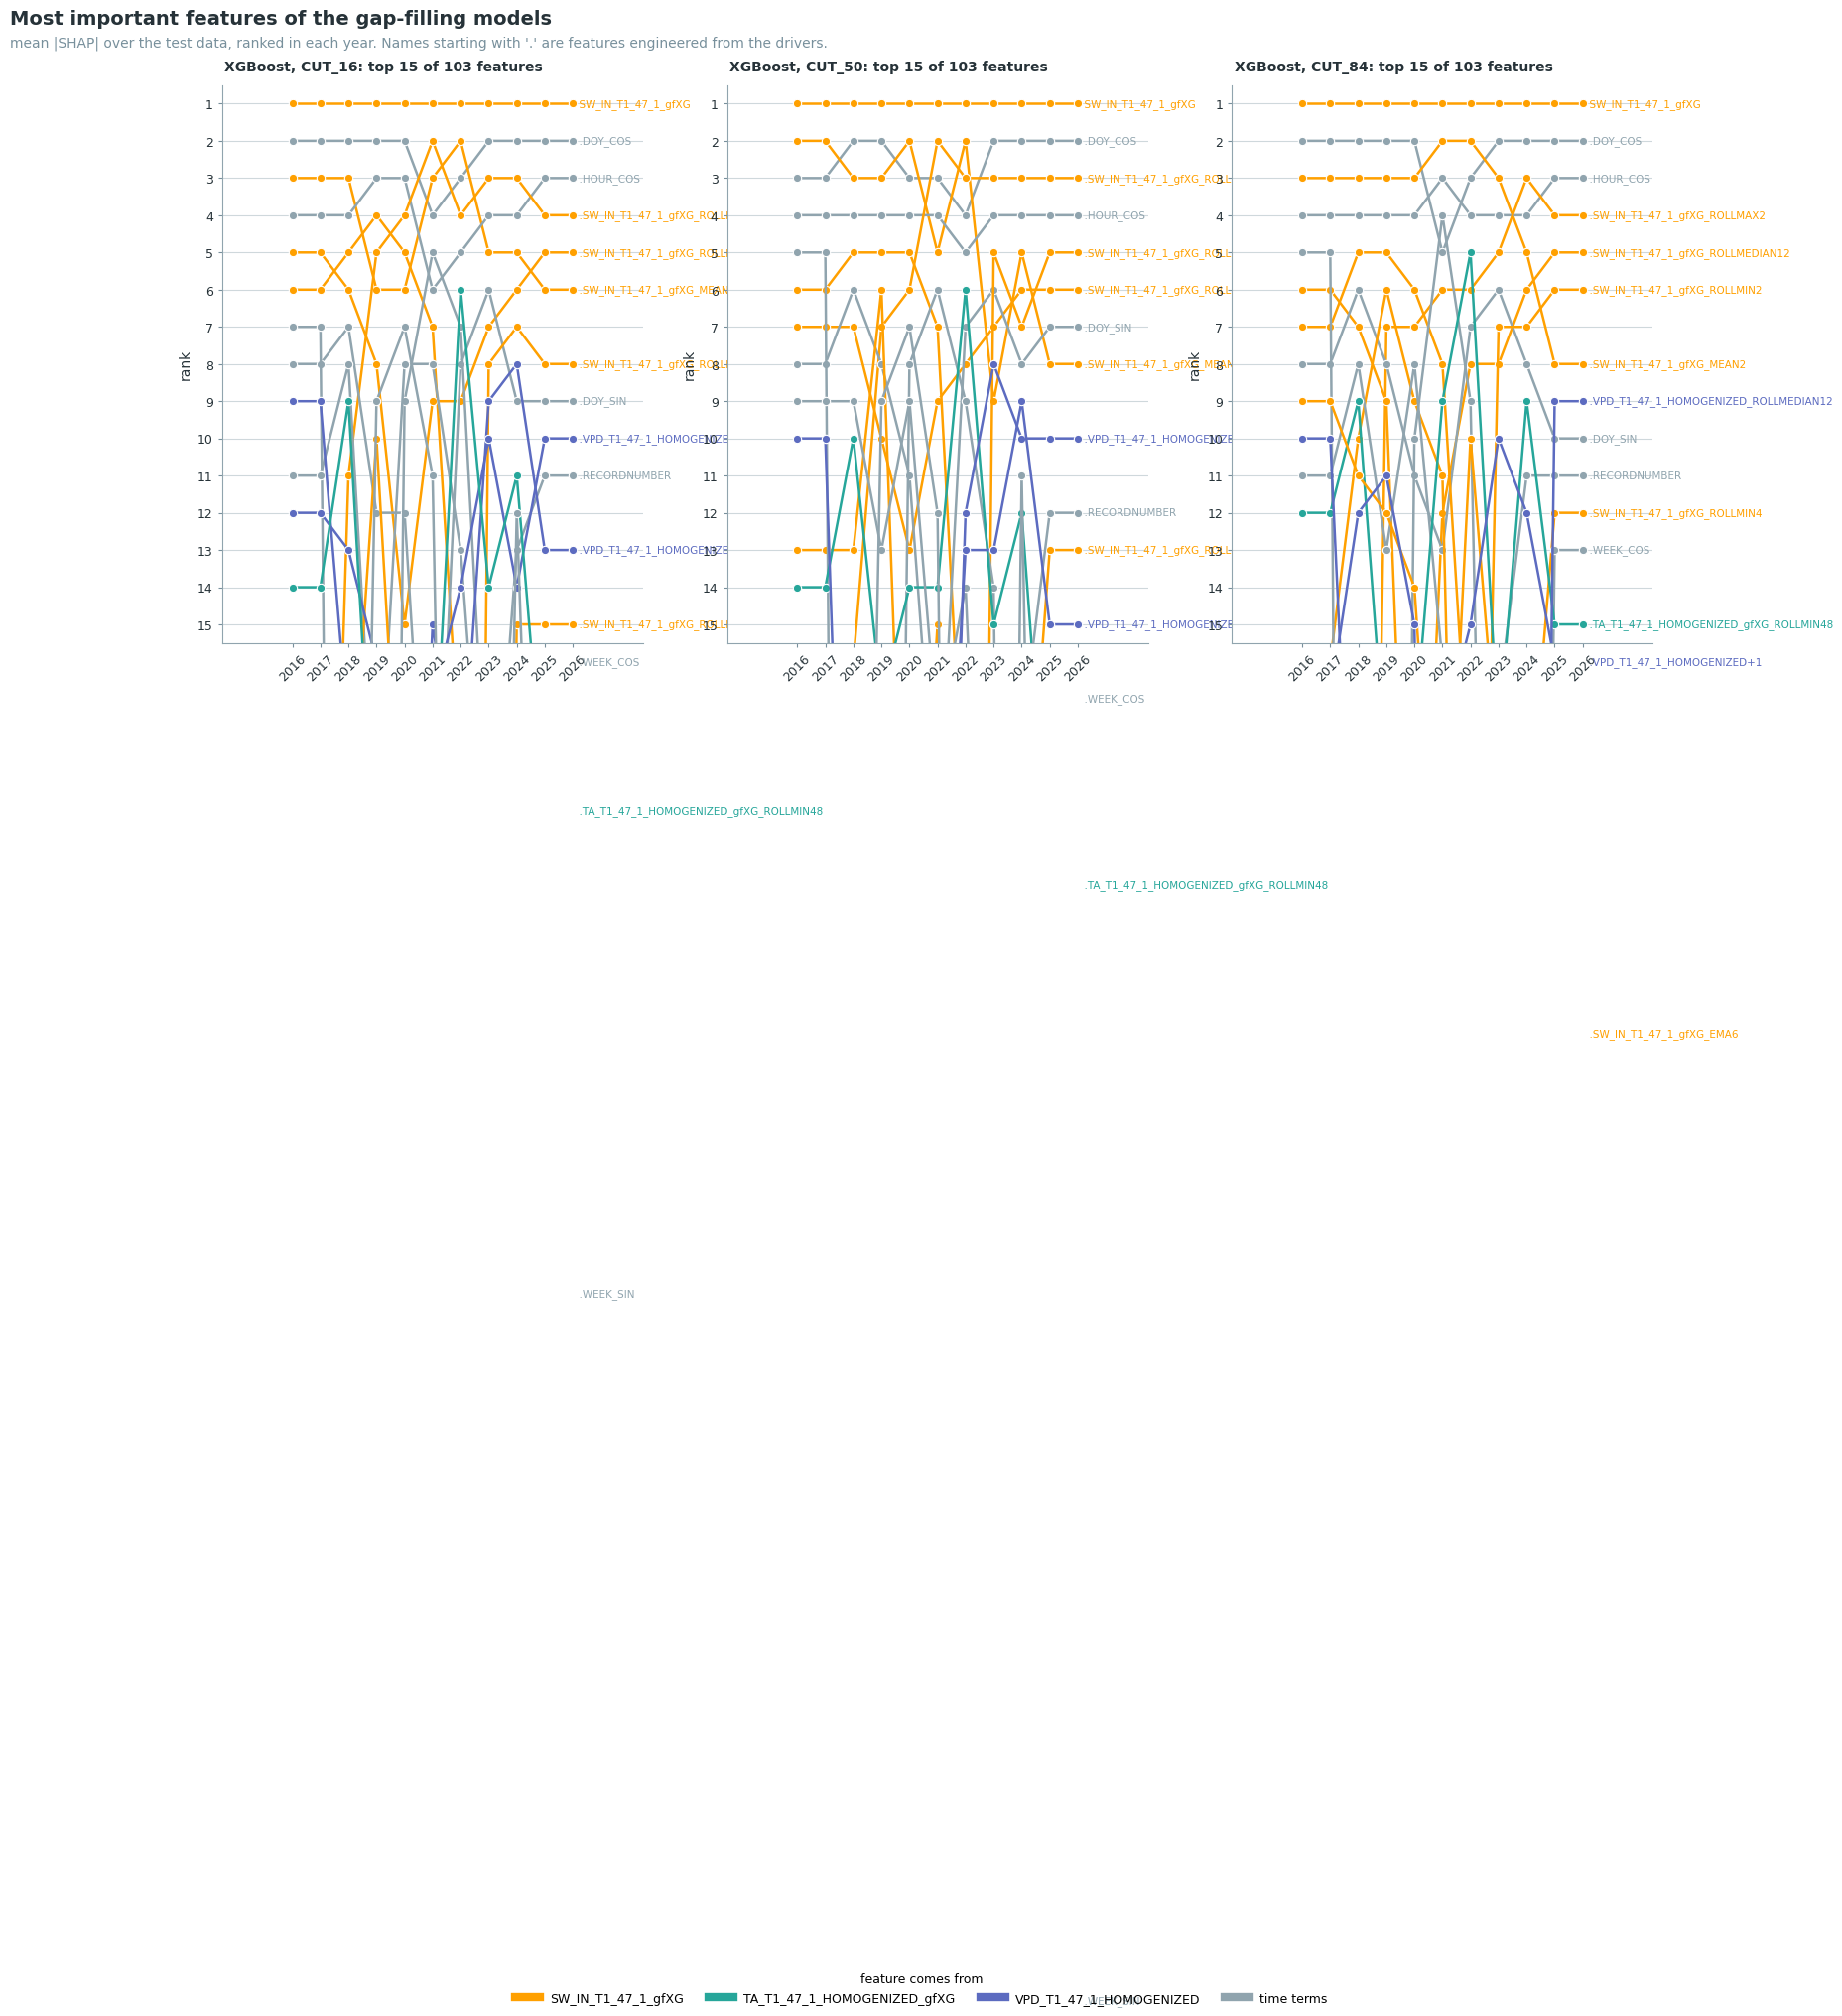

In [45]:
plot_feature_ranks_per_year(data)

## Step 11: result plots

### 📊 Plot: flux by quality class, heatmaps, XGBoost, CUT_50

The highest-quality records (QCF 0), the records the gap-filling used (QCF 0 and 1), the rejected
records, and the gap-filled result, on one colour scale.

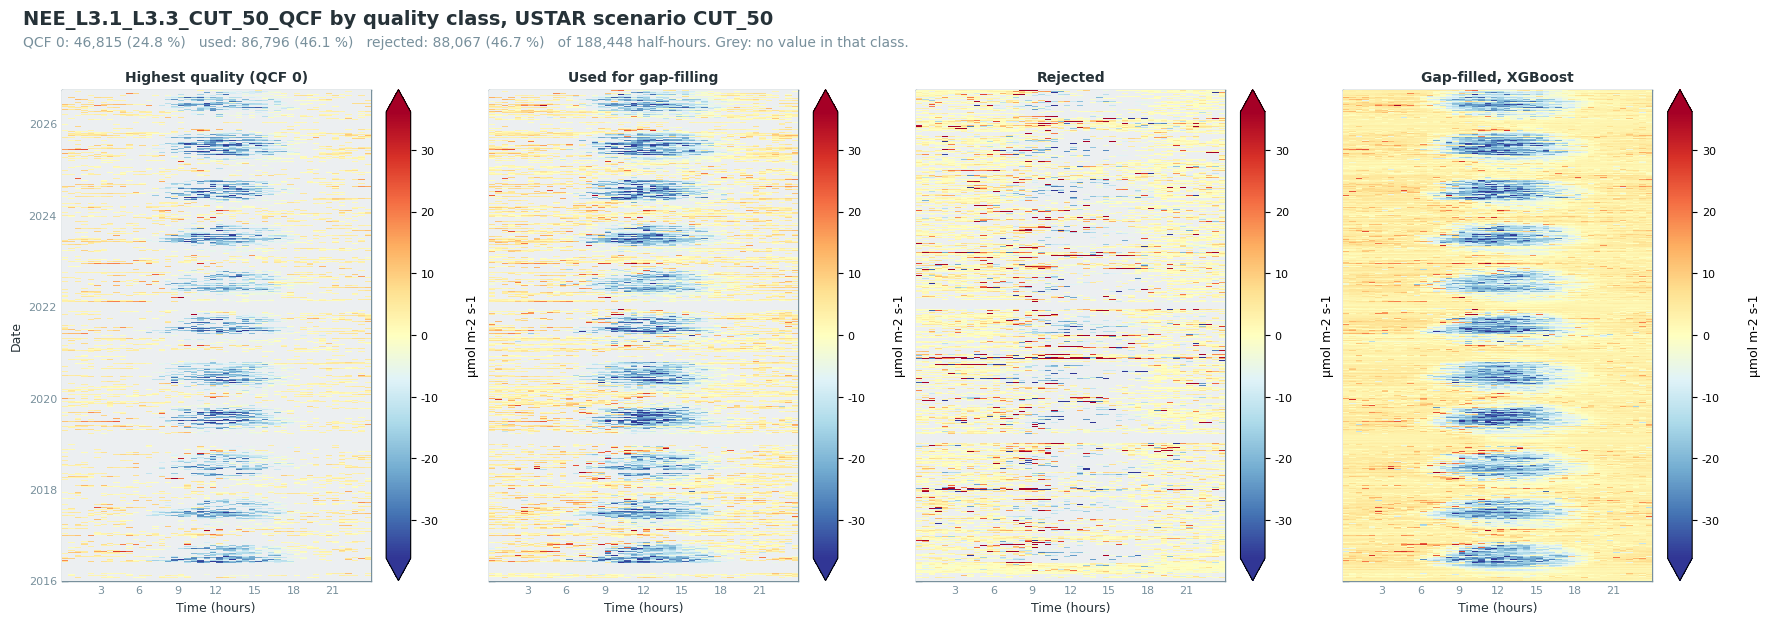

In [46]:
plot_quality_heatmaps(data, ustar_scenario='CUT_50', units=FLUX_UNITS, method='xgb')

### 📊 Plot: flux by quality class, day and night, XGBoost, CUT_50

Daytime and nighttime records by quality class, then the gap-filled result, with measured and
filled records shown apart.

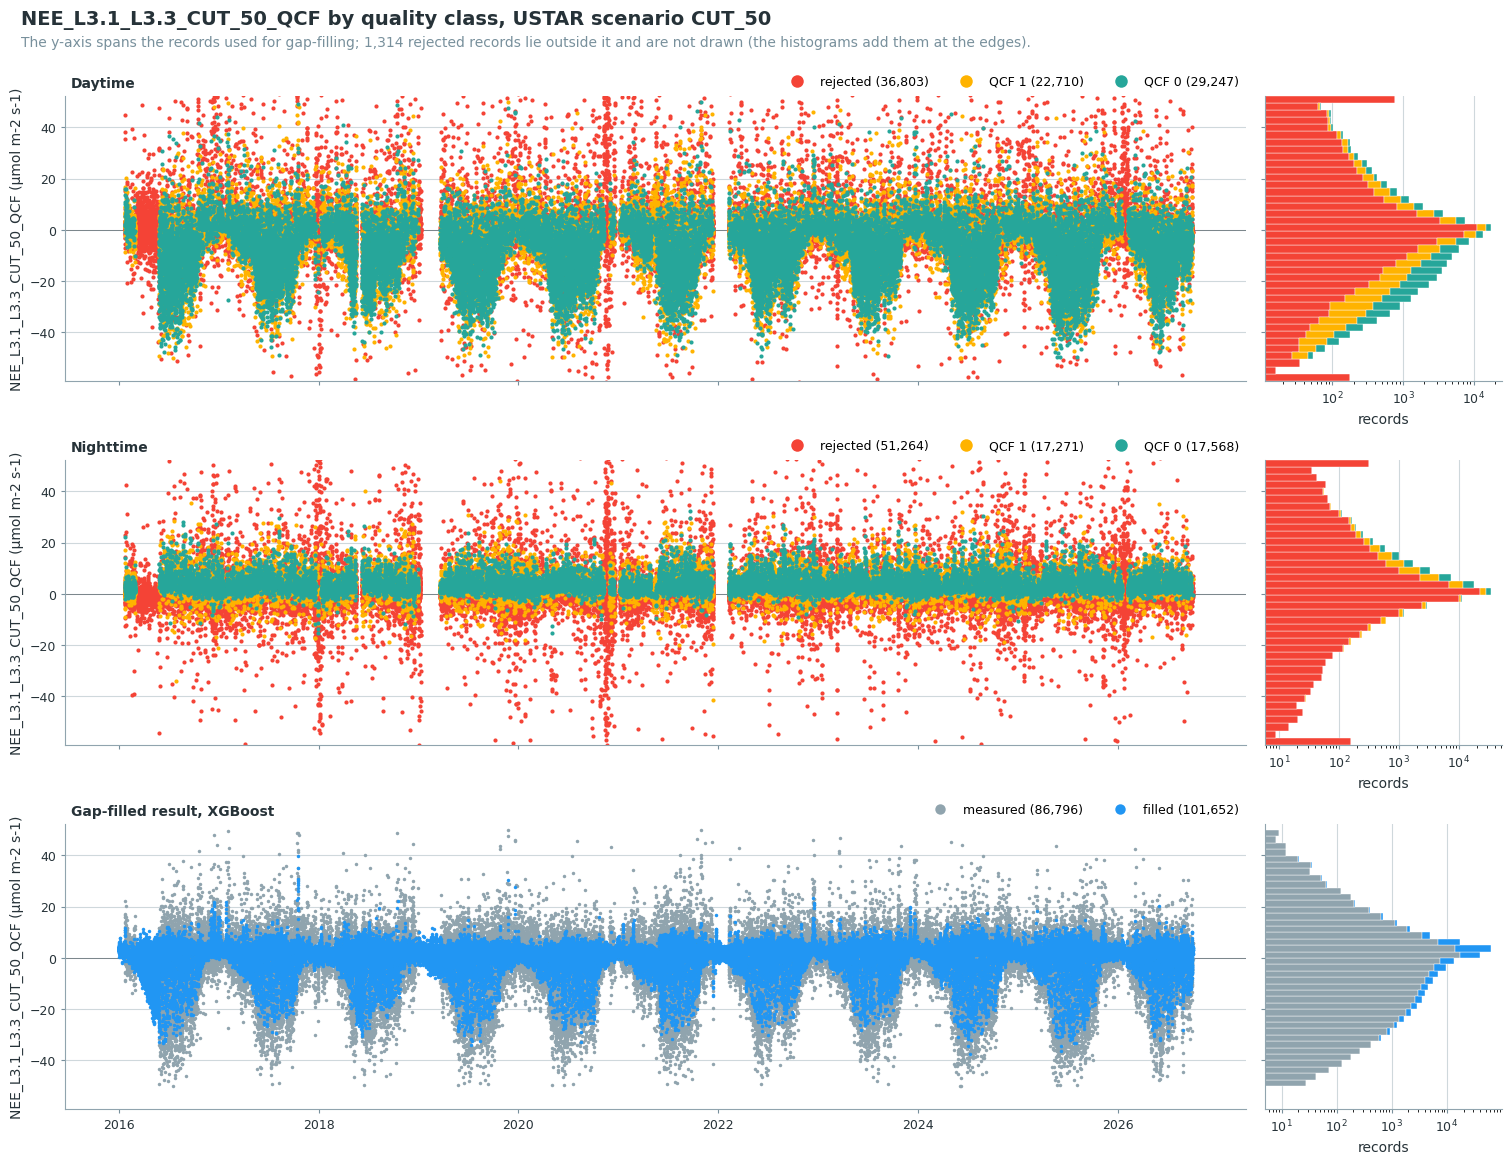

In [47]:
plot_quality_timeseries(data, ustar_scenario='CUT_50', units=FLUX_UNITS, method='xgb')

### 📊 Plot: measured and gap-filled flux, CUT_50

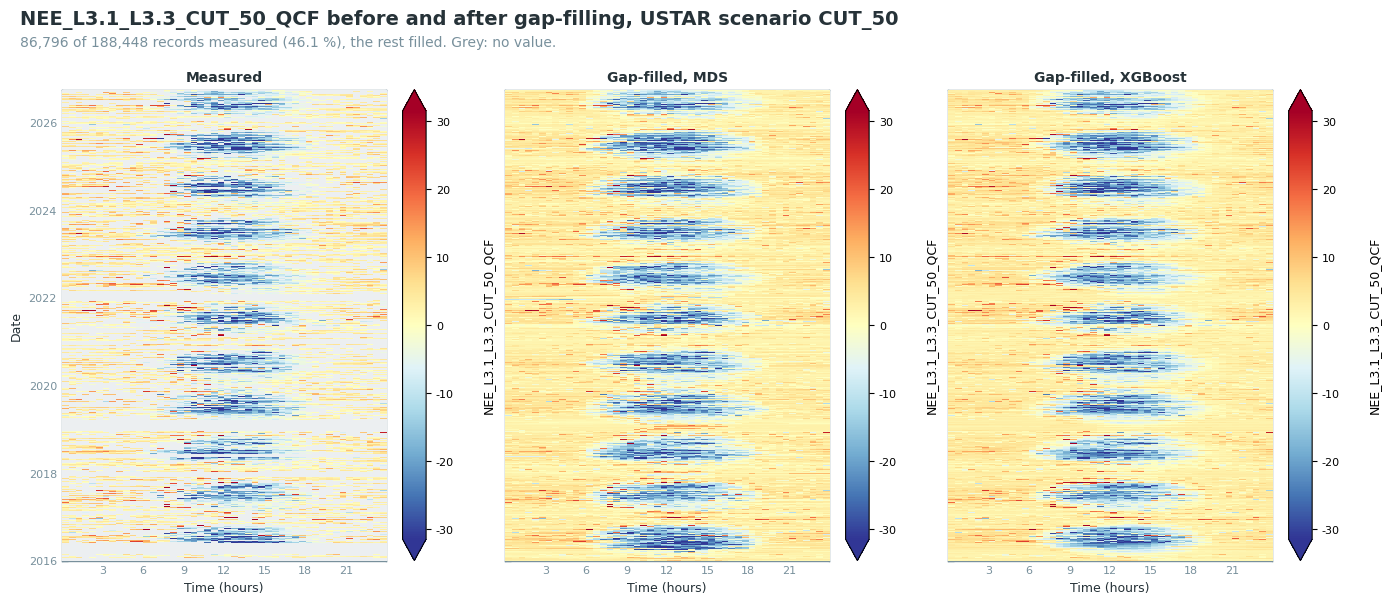

In [48]:
data.plot_gapfilled_heatmaps(ustar_scenario='CUT_50')

### 📊 Plot: cumulative flux, CUT_50

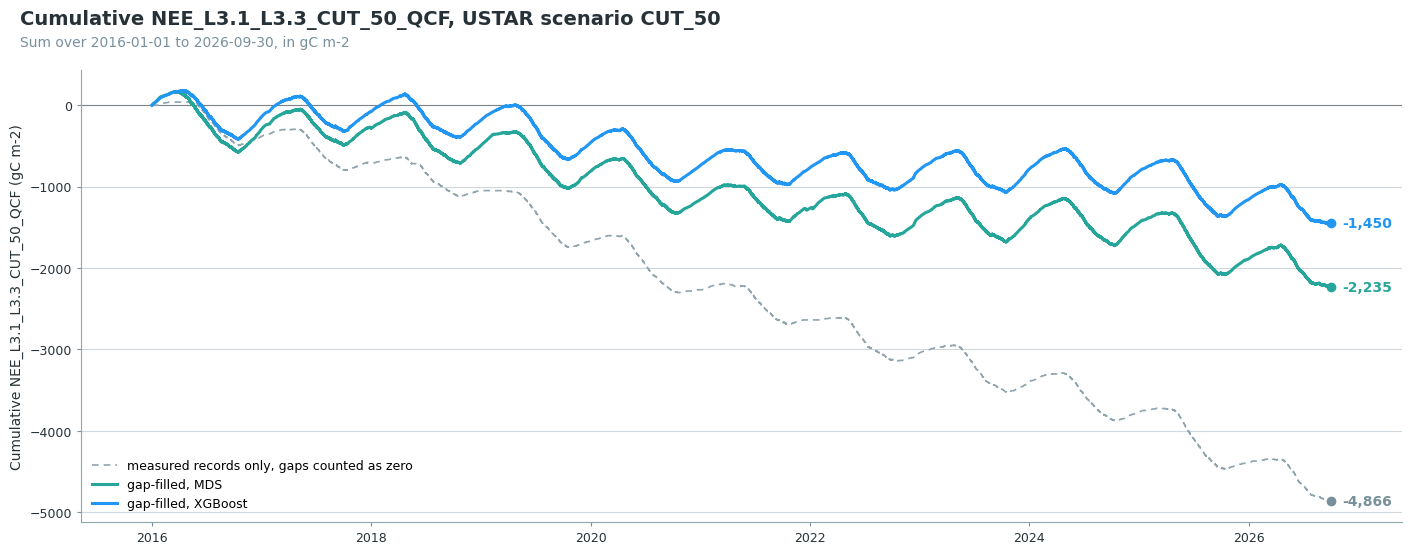

In [49]:
data.plot_cumulative_comparison(
    ustar_scenario='CUT_50',
    conv_factor=UMOL_TO_GC,
    units='gC m-2',
)

### 📊 Plot: cumulative flux of all USTAR scenarios

One line per gap-filling method and USTAR scenario, each method in its own colour. The spread
between CUT_16, CUT_50 and CUT_84 shows how much the annual sum depends on the USTAR threshold. It also contains the variation of the gap-filling model, which
changes with the records each scenario keeps.

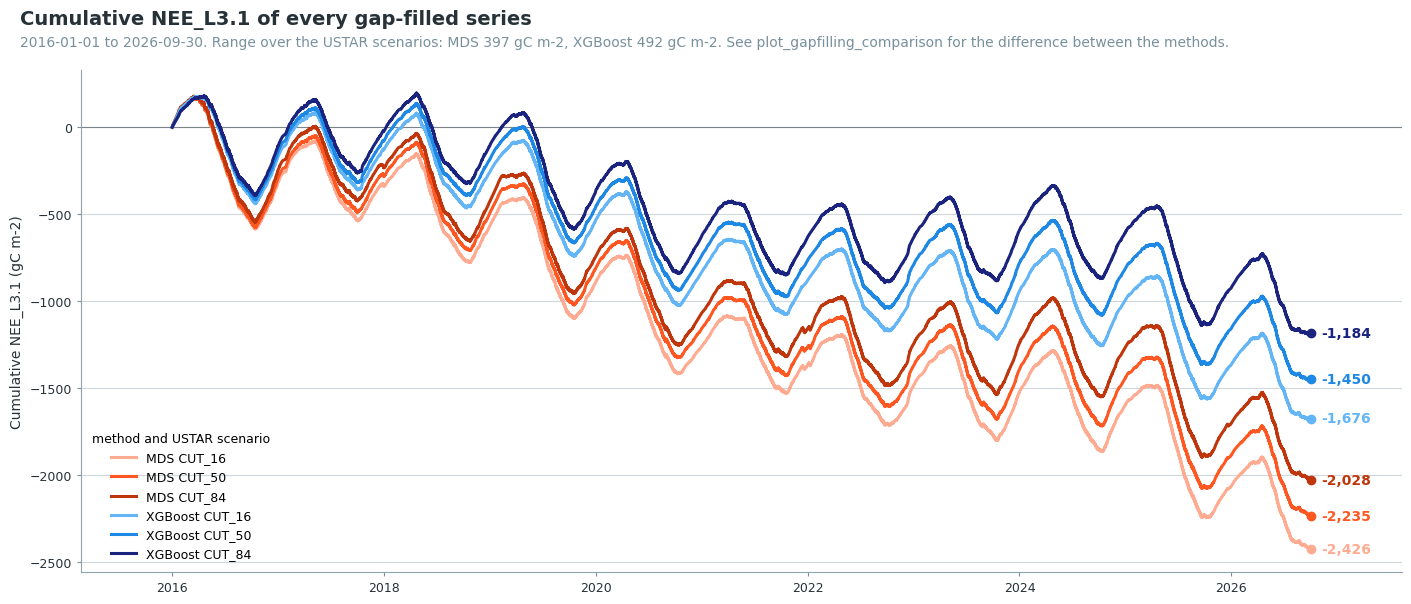

In [50]:
plot_gapfilled_cumulative(
    data,
    gain=UMOL_TO_GC,
    units='gC m-2',
    per_year=False,
)

### 📊 Plot: cumulative flux per year, for each scenario

One row per gap-filling method and one panel per USTAR scenario, on the same y-axis. One line per year, with the mean of all years plus and minus one standard deviation as a band. The legend gives the mean and the standard deviation of the annual totals. In
2016 about 108 days have no measurements: 1 to 10 January, before the first record, and 11 to
22 January and 1 March to 25 May, the start-up periods removed by hand. These include the leaf-out
in spring. The model fills them and learns that season from 2017 and 2018. 2026 ends on
30 September, so its total cannot be compared with full years, and it is left out of the mean and the band.

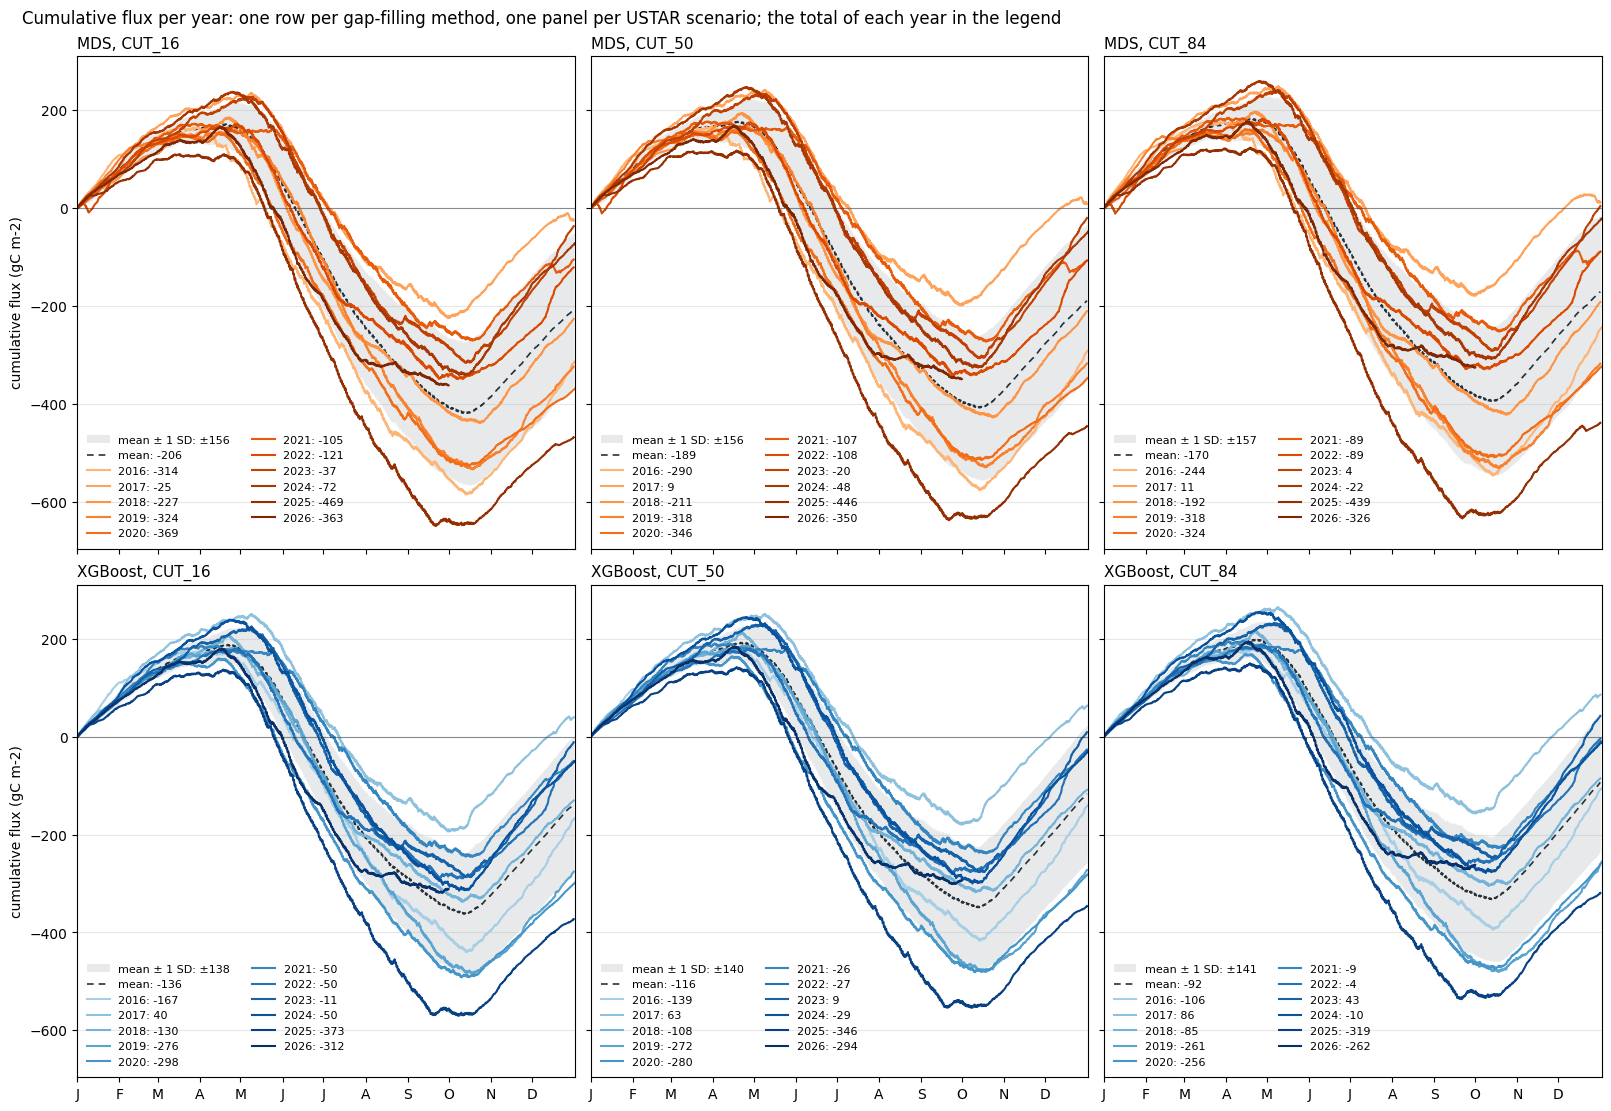

In [51]:
# One row per gap-filling method, one panel per USTAR scenario, on a shared y-axis. Years run
# from light to dark, so the most recent year is the darkest line.
_gf = data.gapfilled_cols()
_names = {'mds': 'MDS', 'xgb': 'XGBoost', 'rf': 'random forest'}
_months = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
# A last year that ends before 31 December stays out of the mean and the band.
_end = data.fpc_df.index[-1]
_partial = [_end.year] if (_end.month, _end.day) != (12, 31) else None
fig, axes = plt.subplots(len(_gf), len(USTAR_SCENARIOS), figsize=(16, 5.5 * len(_gf) + 0.6),
                         sharex=True, sharey=True, layout='constrained', squeeze=False)
for _row, (_method, _cols) in zip(axes, _gf.items()):
    for _ax, _scen in zip(_row, USTAR_SCENARIOS):
        _cum = doy_cumulatives_per_year(data.fpc_df[_cols[_scen]] * UMOL_TO_GC)
        _cum = _cum.loc[:, _cum.notna().any()]
        _years = list(_cum.columns)
        _shades = plt.get_cmap(cp.METHOD_CMAPS.get(_method, 'Greys'))(
            np.linspace(0.35, 1.0, len(_years)) if len(_years) > 1 else [0.85])
        if len(_years) > 1:
            _ref = doy_mean_cumulative(cumulatives_per_year_df=_cum,
                                       excl_years_from_reference=_partial)
            # Day 366 exists only in leap years, so the band stops before it.
            _ref = _ref.loc[_ref.index < 366]
            # The legend gives the mean and SD of the annual totals of the full years.
            _totals = [_cum[_y].dropna().iloc[-1] for _y in _years if _y not in (_partial or [])]
            _end_mean, _end_sd = np.mean(_totals), np.std(_totals, ddof=1)
            _ax.fill_between(_ref.index, _ref['MEAN-SD'], _ref['MEAN+SD'], color=cp.KEPT,
                             alpha=0.3, linewidth=0, label=f'mean ± 1 SD: ±{_end_sd:,.0f}')
            _ax.plot(_ref.index, _ref['MEAN_DOY_TIME'], color=cp.INK, linewidth=1.2,
                     linestyle=(0, (4, 3)), label=f'mean: {_end_mean:,.0f}')
        for _shade, _year in zip(_shades, _years):
            _valid = _cum[_year].dropna()
            _ax.plot(_cum.index, _cum[_year], color=_shade, linewidth=1.5,
                     label=f"{_year}: {_valid.iloc[-1]:,.0f}")
        _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
        cp.style_axes(_ax)
        cp.panel_label(_ax, f"{_names.get(_method, _method)}, {_scen}")
        _ax.set_xticks(_months, ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
        _ax.set_xlim(1, 367)
        _ax.legend(frameon=False, fontsize=8, ncol=1 if len(_years) < 8 else 2)
    _row[0].set_ylabel('cumulative flux (gC m-2)')
_subtitle = ("One row per gap-filling method, one panel per USTAR scenario; the total of each "
             "year in the legend.")
if _partial:
    _subtitle += f" {_end.year} ends on {_end:%d %B} and is left out of the mean and the band."
cp.figure_title(fig, 'Cumulative flux per year', _subtitle)
plt.show()

### Gap-filling methods compared

Both methods fill the same gaps, so the difference between their sums comes from the filled
values alone. The table splits that difference into daytime and nighttime gaps and by gap length,
and scores both methods on the same held-out records: the test records of XGBoost, which MDS also
predicts without using them. These are random single half-hours, so the scores describe short
gaps, while the sums depend more on the long ones.

**Skipped** when `RUN_MDS = False`.

#### 📋 Table: MDS and XGBoost, sums and their difference

In [52]:
if RUN_MDS:
    report_gapfilling_comparison(data, methods=('mds', 'xgb'), gain=UMOL_TO_GC, units='gC m-2');

Gap-filling methods compared: MDS and XGBoost
            sum       sum                    from         from   gaps   gaps    gaps   gaps
USTAR       MDS   XGBoost   difference   day gaps   night gaps      1   2-12   13-48    >48
───────────────────────────────────────────────────────────────────────────────────────────
CUT_16   -2,426    -1,676          749        649          100     31    237     216    266
CUT_50   -2,235    -1,450          785        693           92     16    223     263    284
CUT_84   -2,028    -1,184          844        770           75      2    183     332    327
Sums (gC m-2). difference = XGBoost - MDS over the filled gaps, split into daytime and nighttime 
gaps and by gap length in records.
CUT_16, same 23,017 held-out records: MDS R² 0.63 RMSE 6.33, XGBoost R² 0.73 RMSE 5.45
CUT_50, same 21,634 held-out records: MDS R² 0.65 RMSE 6.24, XGBoost R² 0.74 RMSE 5.36
CUT_84, same 20,140 held-out records: MDS R² 0.66 RMSE 6.26, XGBoost R² 0.74 RMSE 5.43
Held-out records are random single half-hours, so these scores describe short gaps; the sums depend 
more on the long ones.

#### 📊 Plot: where MDS and XGBoost differ

The filled values of both methods at the same gaps, their mean difference by month and hour, the
contribution of each month to the difference of the sums, and the cumulative difference for every
USTAR scenario.

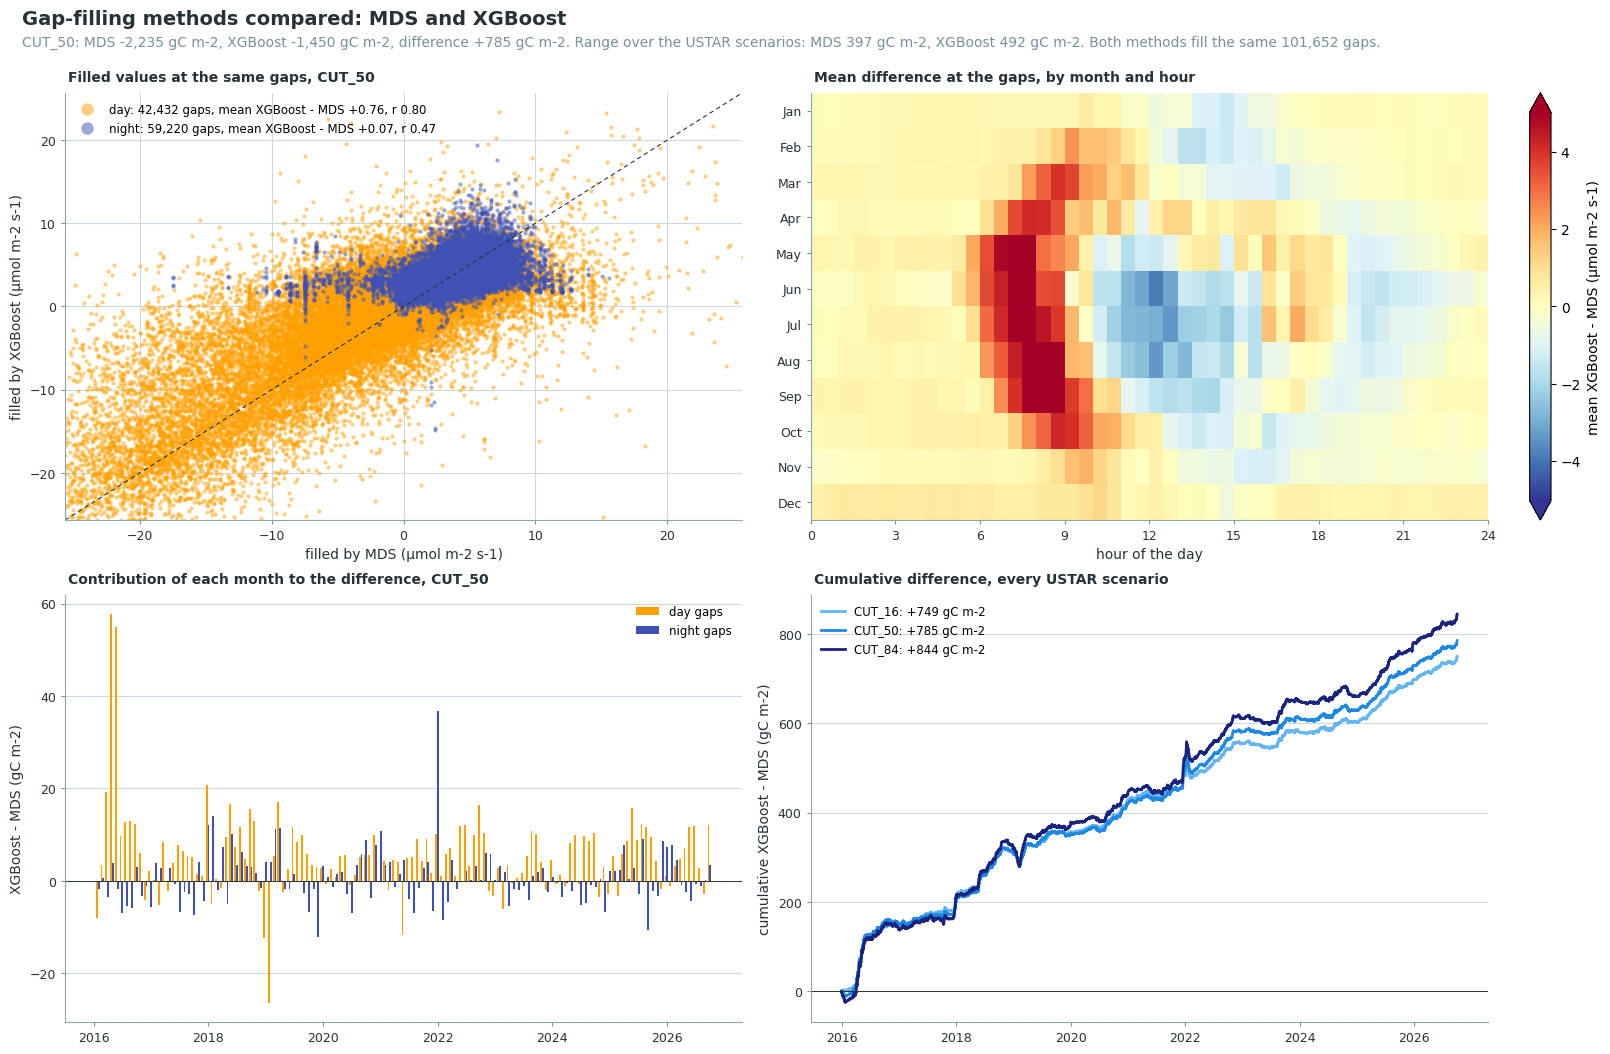

In [53]:
if RUN_MDS:
    plot_gapfilling_comparison(data, ustar_scenario='CUT_50', methods=('mds', 'xgb'),
                               gain=UMOL_TO_GC, units='gC m-2', flux_units=FLUX_UNITS);

## Step 12: uncertainty

The uncertainty of the gap-filled flux follows Pastorello et al. (2020). It is computed for the
`UNC_REF` (CUT_50) series of every gap-filling method that ran, here XGBoost, the method of this
dataset, and MDS. It has two parts:

- **Random uncertainty** (`_RANDUNC`), as in FLUXNET2015 and ONEFlux (Hollinger and Richardson
  2005). For a measured record it is the standard deviation of the measured fluxes within ±7 days
  and ±1 hour under similar meteorological conditions (TA, VPD and SW_IN, with the MDS tolerances),
  if there are more than five such records. Otherwise, and for every gap-filled record, it is the
  median of these standard deviations for similar flux values within ±14 days, as in the ONEFlux
  code. diive adds two further steps so that every record gets a value: the same median over the
  whole record, then the median for the closest flux values. The measured records get the same
  value for every method; the gap-filled records depend on the filled values, so the random
  uncertainty is computed for each method.
- **USTAR uncertainty** (`_USTARUNC`): half the difference between the CUT_84 and the CUT_16 series
  of the same method. FLUXNET2015 filters the flux at 40 USTAR thresholds and takes the 16th and
  84th percentile of the 40 results. This dataset uses three fixed thresholds, so the series
  filtered at the 16th and 84th percentile of the thresholds stand in for these percentiles.

The joint uncertainty (`_JOINTUNC`) combines both for each record: √(RANDUNC² + USTARUNC²). All three
are 1-sigma values in the flux units.

For sums over a day or a year the two parts add up differently. Random errors are independent
between records, so they add in quadrature. The USTAR threshold applies to every record at once,
so its part is half the difference between the sums of CUT_84 and CUT_16. The difference between
the gap-filling methods is not part of the joint uncertainty, as in FLUXNET2015; the annual table
reports it beside it.

### 📋 Table: random uncertainty, records per method

In [54]:
METHOD_NAMES = {'mds': 'MDS', 'xgb': 'XGBoost', 'rf': 'random forest'}
METHOD_COLORS = {_k: _v[1] for _k, _v in cp.METHOD_COLORS.items()}  # the hue of each method
GF_COLS = data.gapfilled_cols()  # {method: {USTAR scenario: gap-filled column}}
_m = data.merged_df(verbose=0)

RANDUNC = {}
for _method, _cols in GF_COLS.items():
    print(f"\n{METHOD_NAMES.get(_method, _method)}, {UNC_REF}")
    RANDUNC[_method] = dv.flux.RandomUncertaintyPAS20(
        df=_m,
        fluxcol=data.nongapfilled_cols()[_method][UNC_REF],
        fluxgapfilledcol=_cols[UNC_REF],
        tacol=TA_F,
        vpdcol=VPD_F,  # kPa
        swincol=SW_IN_F,
        vpd_in_kpa=True,
    )
    RANDUNC[_method].run()
    RANDUNC[_method].report_method_summary()


MDS, CUT_50


> Calculating random uncertainty with window size +/-7 days and +/-1 hours (method 1) ...

> Time needed: 5.61s

> Calculating random uncertainty with window size +/-14 days (method 2) ...

> Time needed: 7.27s

...

METHOD DISTRIBUTION:

Method  Records Percentage
1: Sliding Window (+/-7d, +/-1h) [ONEFlux]    86796      46.1%
 2: Similar Flux Median (+/-14d) [ONEFlux]   133239      70.7%
3: Similar Flux Median (no window)      7499       4.0%
                 4: Nearest Fluxes         0       0.0%

UNCERTAINTY STATISTICS (umol CO2 m-2 s-1):

Statistic Value (umol CO2 m-2 s-1)
     Mean                   3.7920
  Std Dev                   1.9048
      Min                   0.2252
      Max                  25.9764
    Range                  25.7512

================================================================================

### 📋 Table: random, USTAR and joint uncertainty per record

In [55]:
# Per method, the three columns written to the output file. The USTAR term is stored as a
# magnitude: CUT_84 is not always above CUT_16, and the joint uncertainty uses its square.
UNC = {}
for _method, _cols in GF_COLS.items():
    _gf = _cols[UNC_REF]
    _joint = dv.flux.JointUncertaintyPAS20(
        df=pd.DataFrame({f'{_gf}_RANDUNC': RANDUNC[_method].randunc_series,
                         'lower': _m[_cols[UNC_LOWER]],
                         'upper': _m[_cols[UNC_UPPER]]}),
        randunccol=f'{_gf}_RANDUNC',
        scenario_lower_col='lower',
        scenario_upper_col='upper',
        name=f'{_gf}_JOINTUNC',
    )
    _joint.run()
    print(f"\n{METHOD_NAMES.get(_method, _method)}, {UNC_REF}")
    _joint.report_summary()
    _res = _joint.jointunc_results.rename(columns={_joint.scenarionunccol: f'{_gf}_USTARUNC'})
    _res[f'{_gf}_USTARUNC'] = _res[f'{_gf}_USTARUNC'].abs()
    UNC[_method] = _res[[f'{_gf}_RANDUNC', f'{_gf}_USTARUNC', f'{_gf}_JOINTUNC']]
    assert UNC[_method].notna().all().all(), f"a record of {_gf} has no uncertainty"
UNC_EXPORT = pd.concat(UNC.values(), axis=1)

# The flux and its uncertainty of each method in gC m-2 per half-hour, the input of the sums below.
UNC_FRAMES = {
    _method: pd.DataFrame({
        'flux': _m[_cols[UNC_REF]] * UMOL_TO_GC,
        'var': (UNC[_method][f'{_cols[UNC_REF]}_RANDUNC'] * UMOL_TO_GC) ** 2,
        'lower': _m[_cols[UNC_LOWER]] * UMOL_TO_GC,
        'upper': _m[_cols[UNC_UPPER]] * UMOL_TO_GC,
    })
    for _method, _cols in GF_COLS.items()
}


def period_sums(frame, freq):
    """Sums per period and their 1-sigma uncertainty: the random part in quadrature, the USTAR
    part as half the spread of the CUT_84 and CUT_16 sums."""
    s = frame.resample(freq).sum()
    out = pd.DataFrame({'sum': s['flux'], 'random': np.sqrt(s['var']),
                        'USTAR': ((s['upper'] - s['lower']) / 2).abs()})
    out['joint'] = np.sqrt(out['random'] ** 2 + out['USTAR'] ** 2)
    return out


MDS, CUT_50


================================================================================

JOINT UNCERTAINTY (PAS20) SUMMARY

================================================================================

Output column: NEE_L3.1_L3.3_CUT_50_QCF_gfMDS_JOINTUNC  |  records with estimate: 188,448

...

Output column: NEE_L3.1_L3.3_CUT_50_QCF_gfXG_JOINTUNC  |  records with estimate: 188,448

random term      mean: 3.7920  median: 3.3189

scenario term    mean: 0.0604  median: 0.0000

joint            mean: 3.8560  median: 3.3735

================================================================================

### 📋 Table: annual sums with their uncertainty

`random`, `USTAR` and `joint` are 1-sigma uncertainties of the annual sum of each method. The
second table gives the difference between the methods, which is reported beside the joint
uncertainty and not included in it. The last year ends on 30 September.

In [56]:
ANNUAL_UNC = {_method: period_sums(_f, 'YS').rename(index=lambda _t: _t.year)
              for _method, _f in UNC_FRAMES.items()}
print(f"Annual sums of the {UNC_REF} series and their uncertainty (gC m-2, 1 sigma)")
display(pd.concat({METHOD_NAMES.get(_k, _k): _v for _k, _v in ANNUAL_UNC.items()},
                  names=['method', 'year']).round(1))

if len(ANNUAL_UNC) > 1:
    _names = [METHOD_NAMES.get(_k, _k) for _k in ANNUAL_UNC]
    _s = pd.DataFrame({_n: _v['sum'] for _n, _v in zip(_names, ANNUAL_UNC.values())})
    _diff = pd.DataFrame({f'{_b} - {_a}': _s[_b] - _s[_a]
                          for _i, _a in enumerate(_names) for _b in _names[_i + 1:]})
    _diff.index.name = 'year'
    print(f"\nDifference between the methods (gC m-2), not part of the joint uncertainty")
    display(_diff.round(1))

Annual sums of the CUT_50 series and their uncertainty (gC m-2, 1 sigma)


sum  random  USTAR  joint
method  year                             
MDS     2016 -290.0    13.3   34.7   37.2
        2017    8.9    12.9   18.3   22.4
        2018 -210.8    13.0   17.3   21.7
        2019 -317.6    12.5    3.1   12.9
        2020 -346.4    11.1   22.5   25.1
        2021 -107.2    13.5    7.9   15.6
        2022 -107.7    11.3   16.1   19.7
        2023  -20.3    12.1   20.6   23.8
        2024  -48.3    12.6   25.2   28.2
        2025 -446.1    11.5   14.9   18.8
        2026 -349.7     9.2   18.2   20.4
XGBoost 2016 -139.2    13.1   30.4   33.1
        2017   63.5    12.8   23.1   26.4
        2018 -108.5    12.8   22.6   26.0
        2019 -272.3    12.4    7.5   14.5
        2020 -280.1    11.0   21.2   23.9
        2021  -26.4    13.2   20.4   24.3
        2022  -27.0    11.1   23.0   25.5
        2023    9.4    12.0   27.0   29.6
        2024  -29.2    12.5   19.5   23.2
        2025 -346.3    11.4   26.8   29.1
        2026 -293.7     9.1   24.7   26.4


Difference between the methods (gC m-2), not part of the joint uncertainty


,XGBoost - MDS
year,
2016,150.8
2017,54.6
2018,102.4
2019,45.3
2020,66.3
2021,80.7
2022,80.6
2023,29.6
2024,19.0


### 📊 Plot: annual sums with their uncertainty

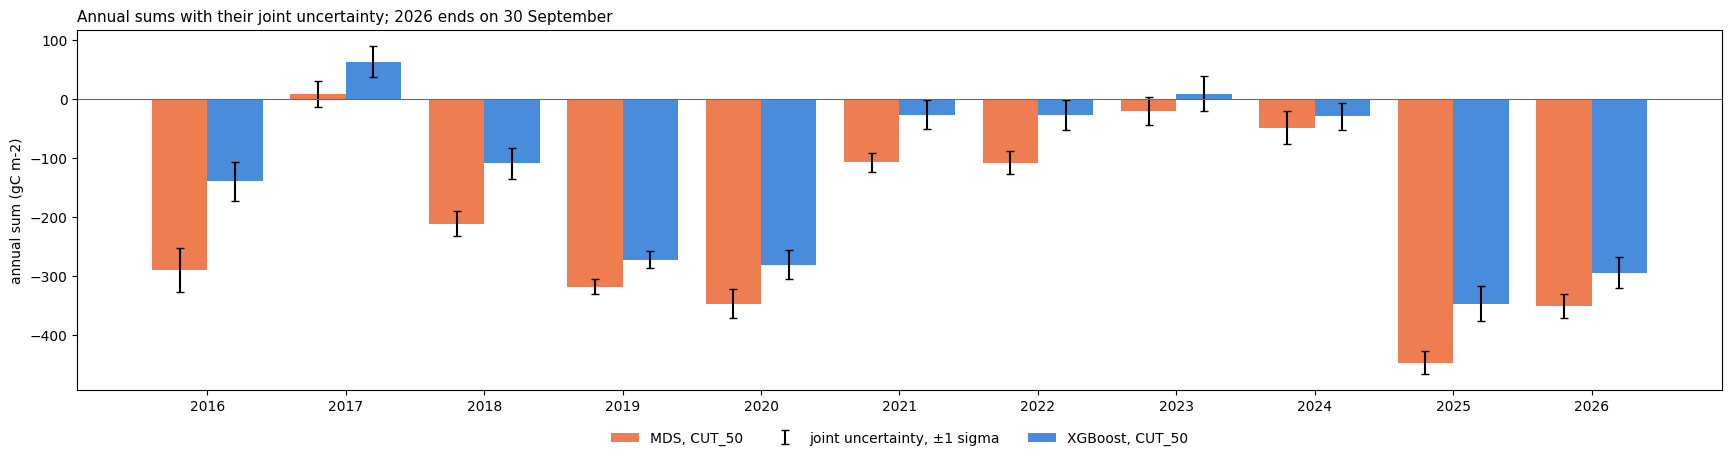

In [57]:
_methods = list(ANNUAL_UNC)
_years = ANNUAL_UNC[_methods[0]].index
_width = 0.8 / len(_methods)
_end = _m.index[-1]
fig, ax = plt.subplots(figsize=(max(8, 1.2 * len(_years) + 4), 5), layout='constrained')
for _i, _method in enumerate(_methods):
    _a = ANNUAL_UNC[_method]
    _x = np.arange(len(_years)) + (_i - (len(_methods) - 1) / 2) * _width
    ax.bar(_x, _a['sum'], _width, color=METHOD_COLORS.get(_method, cp.KEPT),
           label=f'{METHOD_NAMES.get(_method, _method)}, {UNC_REF}')
    ax.errorbar(_x, _a['sum'], yerr=_a['joint'], fmt='none', ecolor=cp.INK, capsize=3,
                linewidth=1, label='joint uncertainty, ±1 sigma' if _i == 0 else None)
ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
ax.set_xticks(np.arange(len(_years)), _years)
ax.set_ylabel('annual sum (gC m-2)')
cp.style_axes(ax)
fig.legend(*ax.get_legend_handles_labels(), loc='outside lower center', frameon=False,
           ncol=len(_methods) + 1, fontsize=9)
cp.figure_title(fig, 'Annual sums with their joint uncertainty',
                f"USTAR scenario {UNC_REF}, error bars ±1 sigma."
                + (f" {_end.year} ends on {_end:%d %B}." if (_end.month, _end.day) != (12, 31)
                   else ""))
plt.show()

### 📊 Plot: cumulative flux per year with its uncertainty

One panel per year, one line and band per gap-filling method. The band is the joint uncertainty,
accumulated from 1 January: the random part in quadrature, the USTAR part as half the spread of
the cumulative CUT_84 and CUT_16 sums. Where the bands of two methods do not overlap, the methods
differ by more than the joint uncertainty.

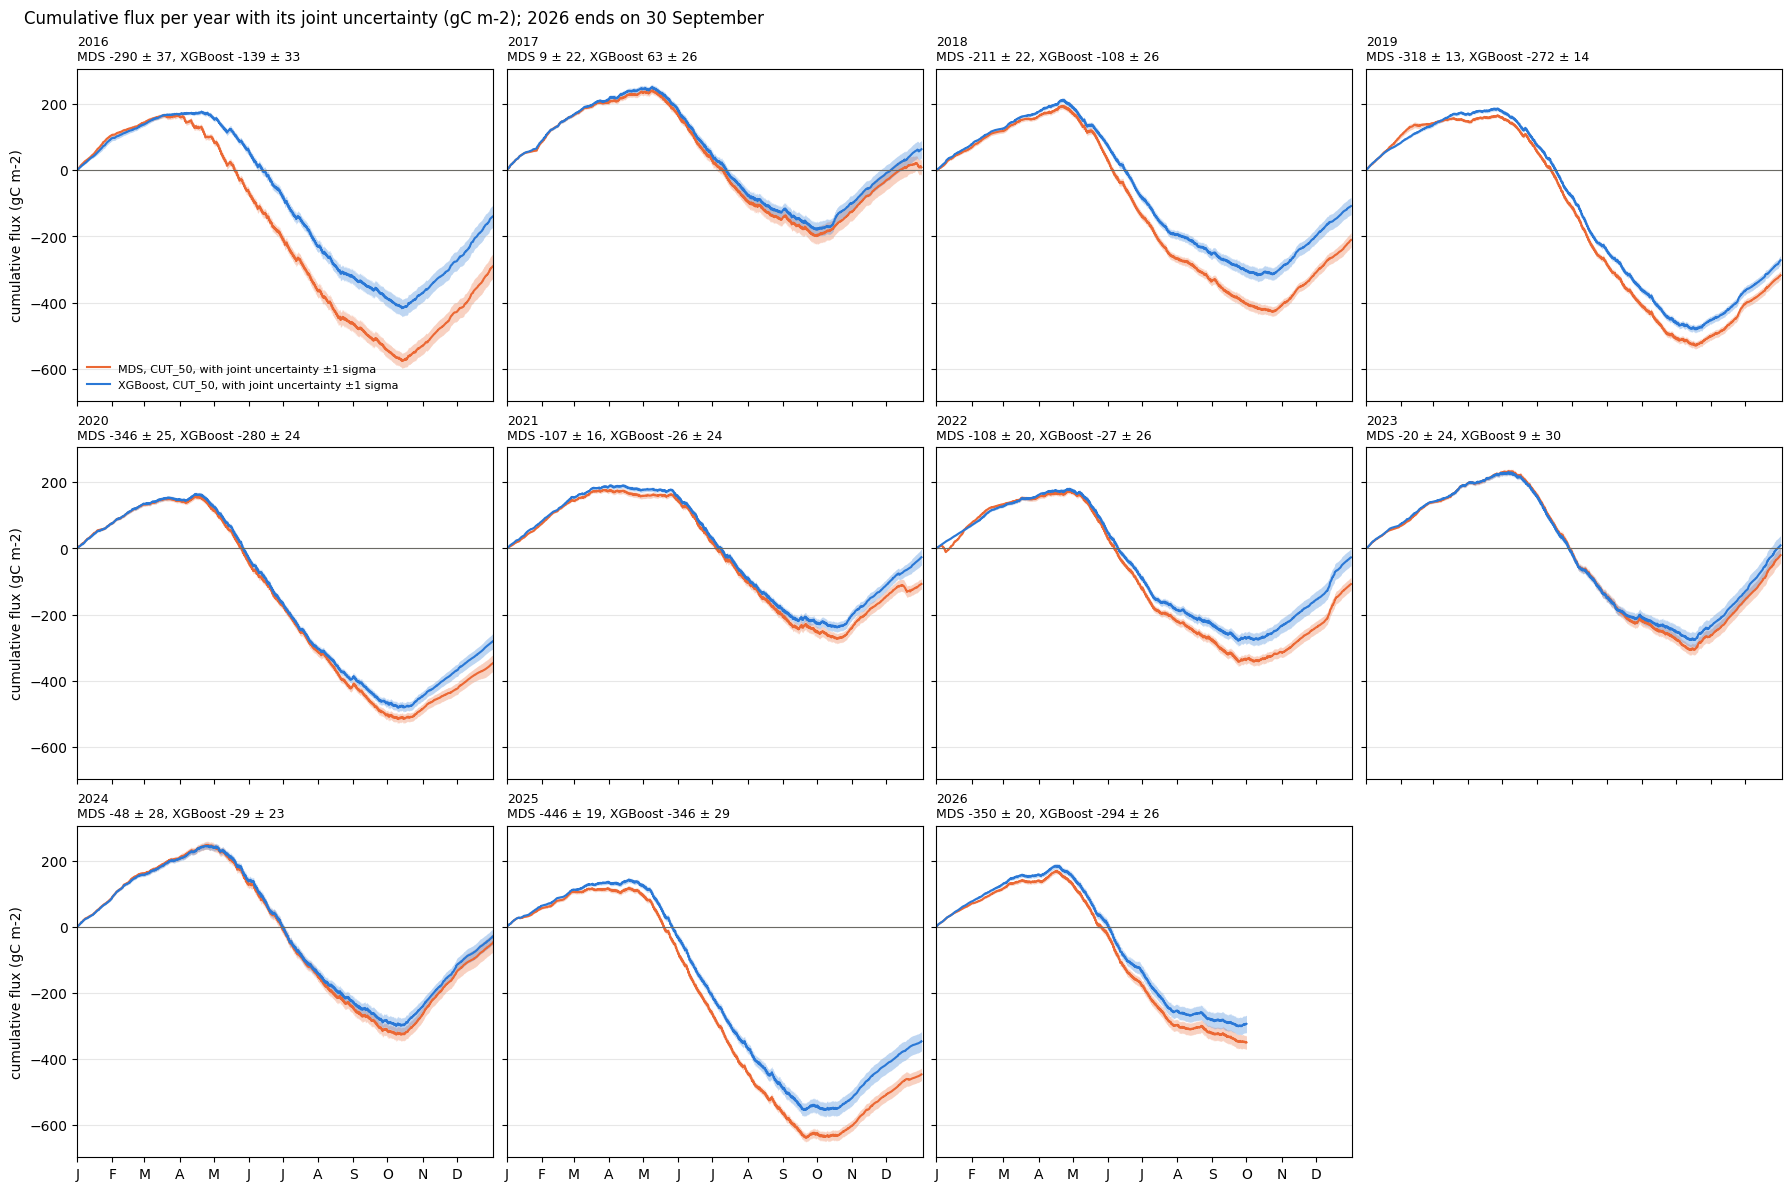

In [58]:
_years = sorted(set(_m.index.year))
_end = _m.index[-1]
_ncol = min(4, len(_years))
_nrow = -(-len(_years) // _ncol)
_month_starts = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
fig, axes = plt.subplots(_nrow, _ncol, figsize=(4.2 * _ncol + 1, 3.8 * _nrow + 1.4), sharex=True,
                         sharey=True, layout='constrained', squeeze=False)
for _ax, _year in zip(axes.flat, _years):
    _totals = []
    for _method, _f in UNC_FRAMES.items():
        _d = _f.loc[str(_year)]
        _doy = (_d.index.dayofyear + (_d.index.hour + _d.index.minute / 60) / 24).to_numpy()
        _cum = _d['flux'].cumsum()
        _joint = np.sqrt(_d['var'].cumsum()
                         + ((_d['upper'].cumsum() - _d['lower'].cumsum()) / 2) ** 2)
        _color = METHOD_COLORS.get(_method, cp.KEPT)
        _name = METHOD_NAMES.get(_method, _method)
        _ax.fill_between(_doy, _cum - _joint, _cum + _joint, color=_color, alpha=0.3,
                         linewidth=0)
        _ax.plot(_doy, _cum, color=_color, linewidth=1.5,
                 label=f'{_name}, {UNC_REF}, with joint uncertainty ±1 sigma')
        _totals.append(f"{_name} {_cum.iloc[-1]:,.0f} ± {_joint.iloc[-1]:,.0f}")
    _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
    cp.style_axes(_ax)
    cp.panel_label(_ax, f"{_year}")
    _ax.text(0.005, 1.0, ", ".join(_totals), transform=_ax.transAxes, ha='left', va='bottom',
             fontsize=8, color=cp.MUTED)
    _ax.set_xticks(_month_starts, ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
    _ax.set_xlim(1, 367)
for _ax in axes.flat[len(_years):]:
    _ax.set_visible(False)
for _row in axes:
    _row[0].set_ylabel('cumulative flux (gC m-2)')
fig.legend(*axes.flat[0].get_legend_handles_labels(), loc='outside lower center', frameon=False,
           ncol=len(UNC_FRAMES), fontsize=9)
cp.figure_title(fig, 'Cumulative flux per year with its joint uncertainty',
                "gC m-2; under each year the annual sum ± its joint uncertainty."
                + (f" {_end.year} ends on {_end:%d %B}." if (_end.month, _end.day) != (12, 31)
                   else ""))
plt.show()

### 📊 Plot: daily sums with their uncertainty

Two panels per gap-filling method: the daily sum with its joint uncertainty, then the uncertainty
of the daily sums and its two parts.

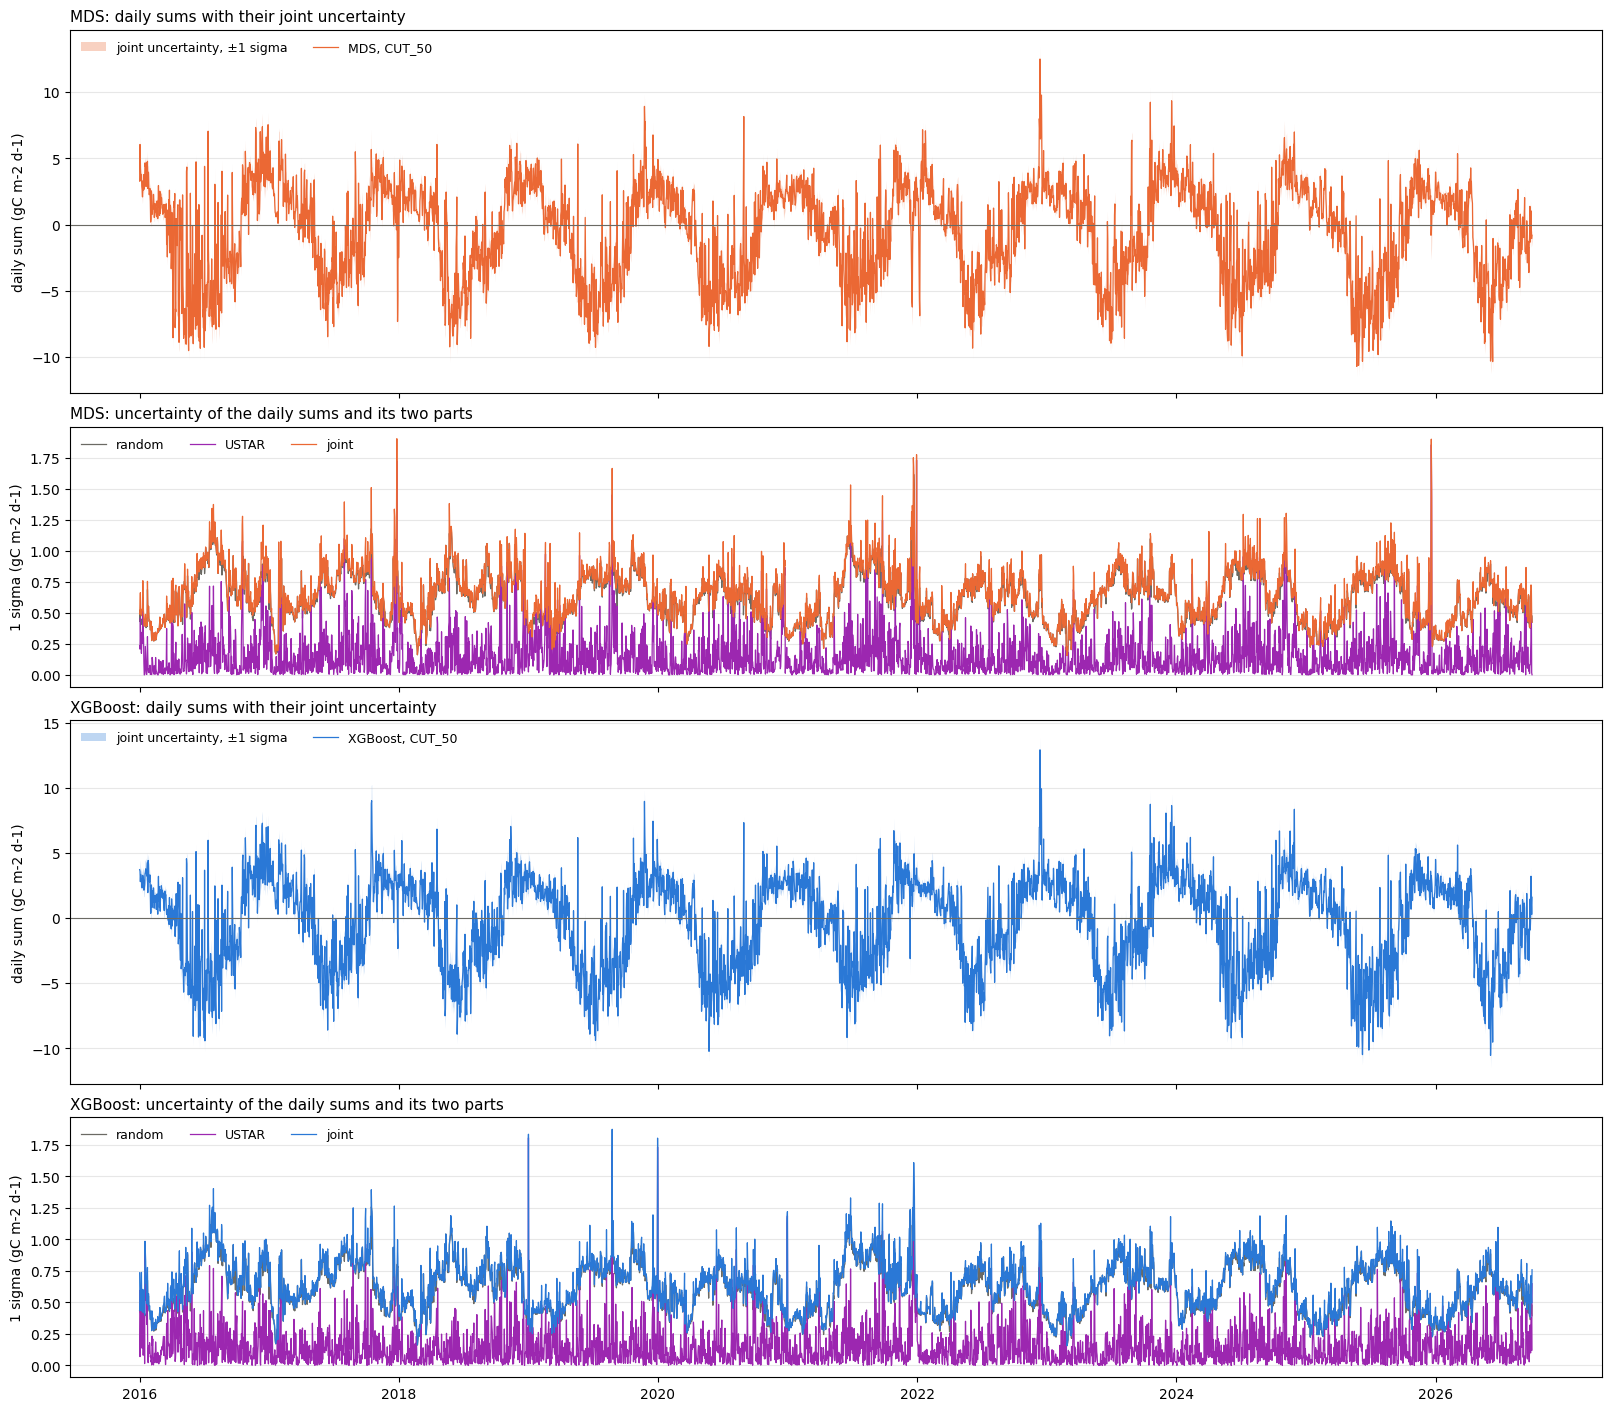

In [59]:
_methods = list(UNC_FRAMES)
fig, axs = plt.subplots(2 * len(_methods), 1, figsize=(16, 7 * len(_methods) + 0.6), sharex=True,
                        layout='constrained', height_ratios=[1.4, 1] * len(_methods))
for _i, _method in enumerate(_methods):
    _day = period_sums(UNC_FRAMES[_method], 'D')
    _color = METHOD_COLORS.get(_method, cp.KEPT)
    _name = METHOD_NAMES.get(_method, _method)
    _top, _bottom = axs[2 * _i], axs[2 * _i + 1]
    _top.fill_between(_day.index, _day['sum'] - _day['joint'], _day['sum'] + _day['joint'],
                      color=_color, alpha=0.3, linewidth=0, label='joint uncertainty, ±1 sigma')
    _top.plot(_day.index, _day['sum'], color=_color, linewidth=0.9, label=f'{_name}, {UNC_REF}')
    _top.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
    _top.set_ylabel('daily sum (gC m-2 d-1)')
    cp.panel_label(_top, f'{_name}: daily sums with their joint uncertainty')
    for _col, _c in (('random', cp.KEPT), ('USTAR', cp.TEST_COLORS[2]), ('joint', _color)):
        _bottom.plot(_day.index, _day[_col], color=_c, linewidth=0.9, label=_col)
    _bottom.set_ylabel('1 sigma (gC m-2 d-1)')
    cp.panel_label(_bottom, f'{_name}: uncertainty of the daily sums and its two parts')
for _ax in axs:
    cp.style_axes(_ax)
    _ax.legend(frameon=False, fontsize=9, loc='upper right', ncol=3)
cp.figure_title(fig, 'Daily sums with their uncertainty',
                f"USTAR scenario {UNC_REF}, 1 sigma: the random part in quadrature, the USTAR part "
                f"as half the spread of the {UNC_UPPER} and {UNC_LOWER} sums.")
plt.show()

### 📊 Plot: heatmaps of the flux and its uncertainty

One row per gap-filling method, date against time of day. The random uncertainty grows with the
size of the flux. The USTAR uncertainty is zero where all three scenarios keep the measured
record, and appears only where a record was removed in one scenario and filled.

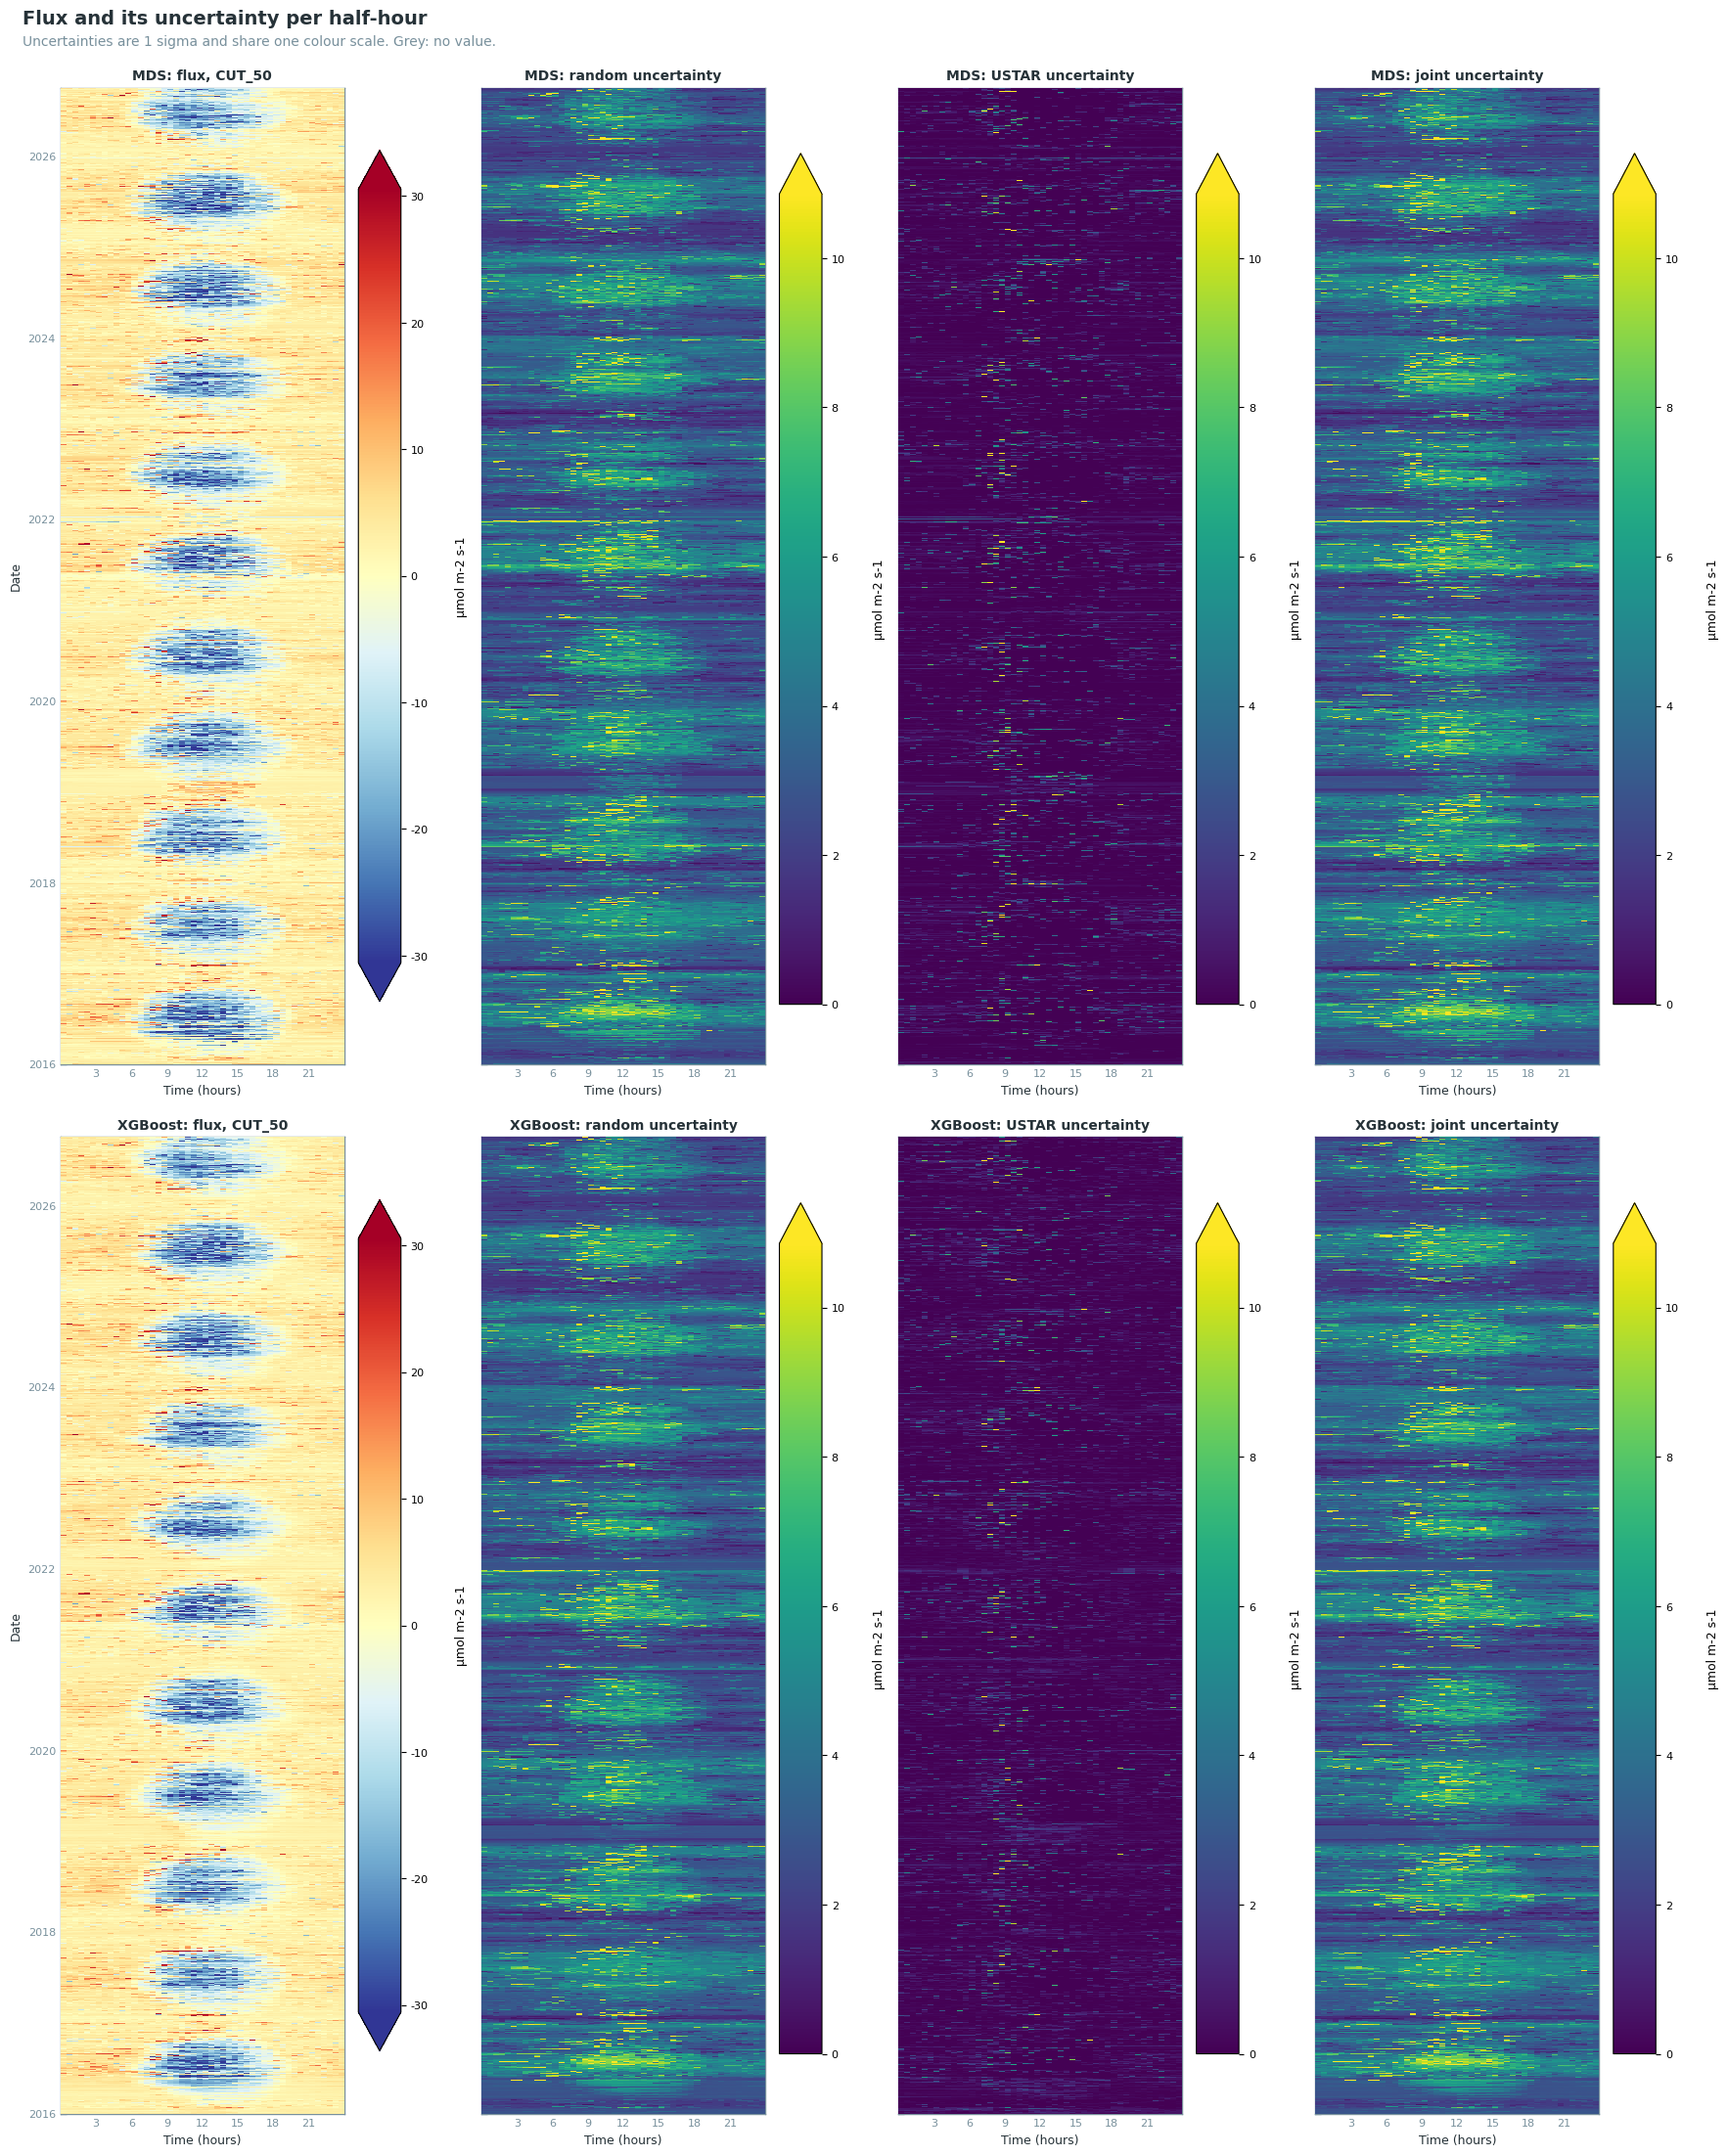

In [60]:
# The flux and its three uncertainties per half-hour. All fluxes share one colour scale, all
# uncertainties another.
_methods = list(UNC_FRAMES)
_flim = max(float(_m[GF_COLS[_k][UNC_REF]].abs().quantile(0.99)) for _k in _methods)
_ulim = max(float(UNC[_k][f'{GF_COLS[_k][UNC_REF]}_JOINTUNC'].quantile(0.99)) for _k in _methods)
fig, axs = plt.subplots(len(_methods), 4, figsize=(17.6, 7 * len(_methods) + 0.6), sharey=True,
                        layout='constrained', squeeze=False)
for _row, _method in zip(axs, _methods):
    _gf = GF_COLS[_method][UNC_REF]
    _name = METHOD_NAMES.get(_method, _method)
    _panels = [
        (f'{_name}: flux, {UNC_REF}', _m[_gf], cp.HEATMAP_CMAP, -_flim, _flim, 'both'),
        (f'{_name}: random uncertainty', UNC[_method][f'{_gf}_RANDUNC'], 'viridis', 0, _ulim, 'max'),
        (f'{_name}: USTAR uncertainty', UNC[_method][f'{_gf}_USTARUNC'], 'viridis', 0, _ulim, 'max'),
        (f'{_name}: joint uncertainty', UNC[_method][f'{_gf}_JOINTUNC'], 'viridis', 0, _ulim, 'max'),
    ]
    for _j, (_ax, (_title, _series, _cmap, _vmin, _vmax, _extend)) in enumerate(zip(_row, _panels)):
        dv.plotting.HeatmapDateTime(series=_series, verbose=False).plot(
            ax=_ax, fig=fig, vmin=_vmin, vmax=_vmax, cmap=_cmap, cb_extend=_extend,
            cb_digits_after_comma='auto', cb_labelsize=8, zlabel=FLUX_UNITS,
            color_bad=cp.NAN_COLOR, as_image=True, format_style=cp.heatmap_style(_title))
        # The unit label next to its colour bar, not halfway to the next panel.
        _cb = _ax.images[-1].colorbar if _ax.images else None
        if _cb is not None:
            _cb.set_label(FLUX_UNITS, size=9, labelpad=4)
        if _j:
            plt.setp(_ax.get_yticklabels(), visible=False)
            _ax.yaxis.get_label().set_visible(False)
cp.figure_title(fig, 'Flux and its uncertainty per half-hour',
                'Uncertainties are 1 sigma and share one colour scale. Grey: no value.')
plt.show()

## 💾 Step 13: export

The output file holds only what this notebook adds: every column the chain created and the three
uncertainty columns of Step 12 for each gap-filling method. The input columns stay unchanged in the
input file; the merge into the fullset joins the outputs of the flux notebooks with it on the
timestamp.

In [61]:
# Only the new columns: the input columns are in the input file and are added back in the merge.
_all = data.merged_df().join(UNC_EXPORT)
out_df = _all[[c for c in _all.columns if c not in df.columns]]
assert out_df.index.equals(df.index), "the output timestamps differ from the input"
assert set(UNC_EXPORT.columns) <= set(out_df.columns), "uncertainty columns missing from the output"
print(f"Uncertainty columns in the output: {list(UNC_EXPORT.columns)}")
print(f"{out_df.shape[0]:,} records x {out_df.shape[1]} columns (input columns left out: "
      f"{_all.shape[1] - out_df.shape[1]})")
filepath = dv.save_parquet(data=out_df, filename=OUTNAME, outpath=OUTPATH)

> New variables from the flux post-processing chain: 65 (L2: 12, L3.1: 9, L3.2: 11, L3.3: 21, 
L4.1: 12)

> No variables in the input data were overwritten, only new variables added.

Uncertainty columns in the output: ['NEE_L3.1_L3.3_CUT_50_QCF_gfMDS_RANDUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfMDS_USTARUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfMDS_JOINTUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG_RANDUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG_USTARUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG_JOINTUNC']
188,448 records x 76 columns (input columns left out: 347)


> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA72\01_FPPC_IRGA72_NEE_2016-2026.09.parquet (0.547 seconds).

***

# End of notebook.

In [62]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-26 19:13:57
Finished: 2026-10-26 19:23:02
Runtime:  00:09:04 (hh:mm:ss)
